# Real-time Object Detection for Self-Driving Cars 
### Fair comparison of 9 detectors

> **Executed notebook.** All outputs below come from one complete run on Kaggle (`FAST_DEV = False`, two NVIDIA T4 GPUs, about 6.1 hours). The conclusions are in section 10.

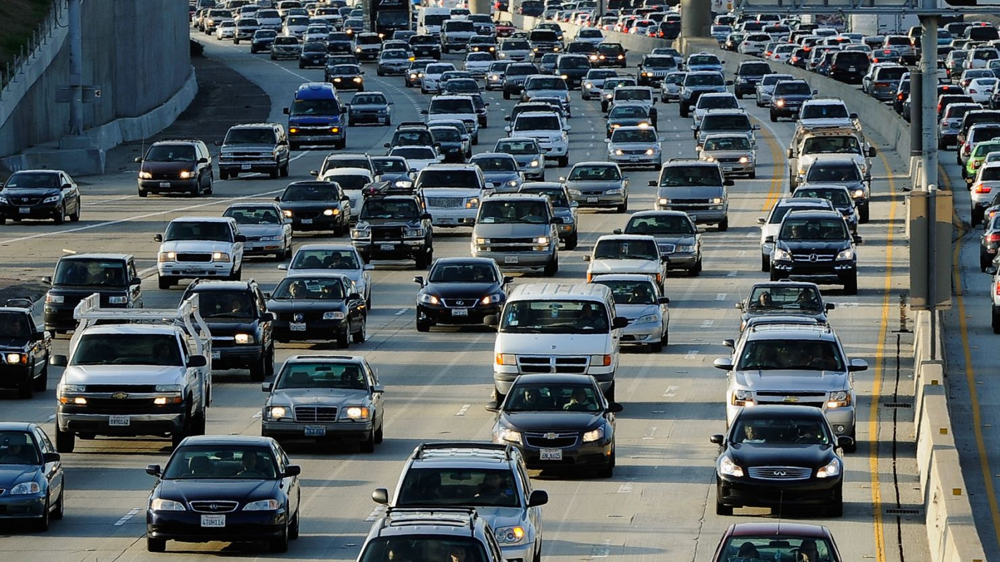

<div style="background-color:#d5eae9; padding:20px; font-size:15px; color:#1f2d2d; line-height:1.55">
<p style="margin-top:0"><b style="font-size:110%">Dataset</b></p>
<p>This notebook uses <b>front-camera road scenes</b>: frames taken from the video of a camera mounted on a car, annotated with bounding boxes for <b>five classes</b>: <b>car, truck, pedestrian, bicyclist and light</b>. It is an object-detection task, and the objects are often small, partly hidden and strongly imbalanced between classes (cars are far more common than bicyclists).</p>
<p>Annotations come as one table with a row per box (<code>frame, xmin, xmax, ymin, ymax, class_id</code>). Because the frames are <b>consecutive video frames</b>, neighbouring images are almost identical; that is why the data is split by <b>contiguous blocks of time</b> rather than at random, into roughly <b>70 % train / 15 % validation / 15 % test</b> (a few frames at every block edge are dropped). Exact frame and box counts are printed in sections 2 and 3.</p>
<p style="margin-bottom:0"><b>Source:</b> Kaggle dataset <a href="https://www.kaggle.com/datasets/mbsoroush/car-camera-photos" style="color:#c27849; font-weight:600">mbsoroush/car-camera-photos</a>.</p>
</div>

<div style="background-color:#d5eae9; padding:20px; font-size:15px; color:#1f2d2d; line-height:1.55">
<p style="margin-top:0"><b style="font-size:110%">Contents</b></p>
<ul style="margin-bottom:0">
<li><a href="#sec0" style="color:#c27849; font-weight:600">0 · Methodology</a></li>
<li><a href="#sec1" style="color:#c27849; font-weight:600">1 · Setup</a></li>
<li><a href="#sec2" style="color:#c27849; font-weight:600">2 · Data: audit, cleaning and EDA</a></li>
<li><a href="#sec3" style="color:#c27849; font-weight:600">3 · Leakage-free split and export</a></li>
<li><a href="#sec4" style="color:#c27849; font-weight:600">4 · Training scripts</a></li>
<li><a href="#sec5" style="color:#c27849; font-weight:600">5 · Train and predict with every model</a></li>
<li><a href="#sec6" style="color:#c27849; font-weight:600">6 · Speed benchmark</a></li>
<li><a href="#sec7" style="color:#c27849; font-weight:600">7 · Evaluation on the test split</a></li>
<li><a href="#sec8" style="color:#c27849; font-weight:600">8 · Visual comparison</a></li>
<li><a href="#sec9" style="color:#c27849; font-weight:600">9 · Training curves, summary and clean-up</a></li>
<li><a href="#sec10" style="color:#c27849; font-weight:600">10 · Conclusions</a></li>
</ul>
</div>

<a class="anchor" id="sec0"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">0 · Methodology</p>

* **Question:** which real-time object detectors give the best **accuracy / speed trade-off** on front-camera road scenes, when every model is trained and evaluated under the *same* leakage-free protocol?
* **Models** (all fine-tuned from COCO-pretrained weights): SSD300-VGG16 · SSDlite320-MobileNetV3 · YOLOv8n · YOLO11n · YOLO11s · RF-DETR nano · RF-DETR small · D-FINE nano · D-FINE small.
* **Data audit and cleaning:** duplicate rows, reversed boxes, boxes outside the image and tiny boxes are handled before anything else, followed by a full EDA.
* **Split:** a **time-based split**. The frames are consecutive video frames, so a random split would leak near-identical images between train and test. Frames are sorted by timestamp and cut into contiguous blocks; whole blocks go to train / val / test (class balance optimised) and a few frames at every block edge are dropped.
* **Training:** every model sees the same data and uses its own recommended fine-tuning recipe, with a wall-clock cap. The validation split picks the checkpoint; the **test split is used once**, at the end.
* **Evaluation:** **one evaluator for all models** (pycocotools): mAP50-95, mAP50, AP by object size and per-class AP. mAP uses all detections with score > 0.001 (max. 100 per image); precision / recall / F1 are reported at a fixed operating point (score ≥ 0.25, IoU ≥ 0.5).
* **Speed:** measured separately, at **batch size 1**, on an otherwise idle GPU, end-to-end (image in → final detections out, NMS included where a model needs it), in **FP32**.
* **Visual comparison:** the predictions of every model are drawn on the same test images.
* **Known deviations from a perfectly identical setup (stated honestly in the results):** each model keeps its own native input size (SSD is fixed at 300 / 320, the RF-DETR variants have their own resolution, YOLO and D-FINE use the dataset size), and checkpoint selection follows each framework's convention (validation mAP in all cases).

<a class="anchor" id="sec1"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">1 · Setup</p>

This section installs the required packages, defines the experiment configuration (model registry, epochs, time caps and GPU queues) and verifies the environment, repairing known version conflicts automatically.

<div style="background-color:#d5eae9; padding:20px; font-size:15px; color:#1f2d2d; line-height:1.55">
<p style="margin-top:0"><b style="font-size:110%">Environment</b></p>
<ul style="margin-bottom:0">
<li>The experiment is designed for <b>Kaggle with two NVIDIA T4 GPUs</b> and internet access, which is needed to download the COCO-pretrained weights. Input data: <a href="https://www.kaggle.com/datasets/mbsoroush/car-camera-photos" style="color:#c27849; font-weight:600">mbsoroush/car-camera-photos</a>.</li>
<li>Each model runs in its own process: a failing model is logged and skipped, and the remaining models continue.</li>
<li style="margin-bottom:0">Every model has a time cap and the notebook stops starting new work before Kaggle's 12 h limit.</li>
</ul>
</div>

<div style="background-color:#d5eae9; padding:20px; font-size:15px; color:#1f2d2d; line-height:1.55">
<p style="margin-top:0"><b style="font-size:110%">How the notebook was run</b></p>
<ol style="margin-bottom:0">
<li><b>Smoke test (<code>FAST_DEV = True</code>).</b> A switch in the configuration cell runs the <b>whole pipeline on a tiny subset</b> (360 / 120 / 120 train / validation / test frames, one epoch per model, about 30–50 min): training, prediction, speed benchmark, evaluation and plots for every model. It confirms that every model works end to end before hours of GPU time are spent.</li>
<li><b>Environment repairs.</b> The first smoke test exposed two package conflicts that affected RF-DETR and D-FINE: a setuptools version without <code>pkg_resources</code>, and a <code>torchaudio</code> build that no longer matched the upgraded torch. The install and environment cells now handle both. A second smoke test, restricted to the affected models with the <code>ONLY_MODELS</code> option, passed.</li>
<li><b>Full experiment (<code>FAST_DEV = False</code>).</b> All nine models on the full data, about <b>6.1 h</b> on two T4 GPUs. All results and figures in this notebook come from this run.</li>
<li style="margin-bottom:0"><b>Reproducing.</b> The notebook needs the dataset, a GPU T4 x2 accelerator and internet access. The <code>FAST_DEV</code> switch selects between the smoke test and the full run, and the notebook is otherwise unchanged between the two.</li>
</ol>
</div>


In [1]:
# ---- 1. Install what is needed (one package at a time, so one failure cannot block the others) ----
import subprocess, sys

def pip(*args):
    r = subprocess.run([sys.executable, "-m", "pip", *args], capture_output=True, text=True)
    return r.returncode == 0, r.stderr[-600:]

for pkg in ["pycocotools", "ultralytics", "rfdetr[train]", "transformers>=4.52"]:
    ok, err = pip("install", "-q", pkg)
    print(("OK     " if ok else "FAILED ") + pkg)
    if not ok:
        print(err)

# Known side effects of the installs above (seen on Kaggle):
#  * setuptools >= 82 no longer ships `pkg_resources`, which pytorch-lightning (used by RF-DETR) still imports
#  * the upgraded torch no longer matches the pre-installed torchaudio, which makes `import transformers` fail
ok, err = pip("install", "-q", "setuptools<81")
print(("OK     " if ok else "FAILED ") + "setuptools<81 (keeps pkg_resources available)")
ok, err = pip("uninstall", "-y", "torchaudio")
print(("OK     " if ok else "FAILED ") + "removed torchaudio (not needed here, only breaks transformers)")

OK     pycocotools
OK     ultralytics
OK     rfdetr[train]
OK     transformers>=4.52
OK     setuptools<81 (keeps pkg_resources available)
OK     removed torchaudio (not needed here, only breaks transformers)


In [2]:
# ---- 2. Configuration ----
import os, sys, json, time, math, random, shutil, subprocess, threading, re, signal, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# =====================================================================================
FAST_DEV = False     # True : smoke test of the WHOLE pipeline on a tiny subset (run this first!)
                     # False: the full experiment
# =====================================================================================
ONLY_MODELS = None   # Only used when FAST_DEV is True, e.g. ["yolov8n", "dfine_nano"] to smoke-test just those.
                     # A full run (FAST_DEV = False) ALWAYS trains all 9 models.
SEED = 42
GLOBAL_DEADLINE_H = 10.5     # the notebook stops starting new work after this (Kaggle limit is 12 h)
REALTIME_FPS = 30            # "real-time" = at least this many frames per second at batch size 1
KEEP_DATA_COPY = False       # keep the exported dataset copy in the output folder?
VIS_CONF = 0.30              # score threshold used when drawing predictions

CLASS_NAMES = ["car", "truck", "pedestrian", "bicyclist", "light"]   # class_id 1..5 -> verify in the gallery below
SPLIT_RATIOS = {"train": 0.70, "val": 0.15, "test": 0.15}
DEV_FRAMES = {"train": 360, "val": 120, "test": 120}                 # used only when FAST_DEV

WORK = Path(os.environ.get("WORK_DIR", "/kaggle/working"))
INPUT_ROOT = Path(os.environ.get("INPUT_ROOT", "/kaggle/input"))
OUT, DATA, RES = WORK / "outputs", WORK / "data", WORK / "results"
SCRIPTS, LOGS = OUT / "scripts", OUT / "logs"
for d in (OUT, DATA, RES):                   # clean start (re-running this cell resets the experiment)
    if d.exists():
        shutil.rmtree(d)
for d in (OUT, DATA, RES, SCRIPTS, LOGS, OUT / "preds", OUT / "meta", OUT / "weights", OUT / "runs"):
    d.mkdir(parents=True, exist_ok=True)

# ---- model registry: epochs, time cap (minutes) and recipe per model ----
MODELS = {
 "yolov8n":      dict(label="YOLOv8n",          family="YOLO",    script="train_yolo.py",   weights="yolov8n.pt", epochs=25, cap_min=75,  batch=16, self_cap=True),
 "yolo11n":      dict(label="YOLO11n",          family="YOLO",    script="train_yolo.py",   weights="yolo11n.pt", epochs=25, cap_min=75,  batch=16, self_cap=True),
 "yolo11s":      dict(label="YOLO11s",          family="YOLO",    script="train_yolo.py",   weights="yolo11s.pt", epochs=25, cap_min=90,  batch=16, self_cap=True),
 "ssd300":       dict(label="SSD300 (VGG16)",   family="SSD",     script="train_ssd.py",    kind="ssd300",    epochs=10, cap_min=90,  batch=16, lr_head=5e-4, lr_backbone=1e-4, self_cap=True),
 "ssdlite320":   dict(label="SSDlite320 (MNv3)",family="SSD",     script="train_ssd.py",    kind="ssdlite320",epochs=20, cap_min=60,  batch=32, lr_head=1e-3, lr_backbone=3e-4, self_cap=True),
 "rfdetr_nano":  dict(label="RF-DETR nano",     family="RF-DETR", script="train_rfdetr.py", epochs=10, cap_min=100, batch=8, accum=2, lr=1e-4, self_cap=False),
 "rfdetr_small": dict(label="RF-DETR small",    family="RF-DETR", script="train_rfdetr.py", epochs=10, cap_min=130, batch=8, accum=2, lr=1e-4, self_cap=False),
 "dfine_nano":   dict(label="D-FINE nano",      family="D-FINE",  script="train_dfine.py",  hf_id="ustc-community/dfine-nano-coco",  epochs=10, cap_min=90,  batch=8, accum=2, lr=1e-4, lr_backbone=2e-5, self_cap=True),
 "dfine_small":  dict(label="D-FINE small",     family="D-FINE",  script="train_dfine.py",  hf_id="ustc-community/dfine-small-coco", epochs=10, cap_min=120, batch=8, accum=2, lr=1e-4, lr_backbone=2e-5, self_cap=True),
}
# two queues -> one per GPU (balanced by expected duration); with one GPU everything runs sequentially
QUEUE_PLAN = [["dfine_nano", "yolov8n", "yolo11n", "yolo11s", "ssd300"],
              ["rfdetr_nano", "dfine_small", "ssdlite320", "rfdetr_small"]]

if not FAST_DEV:
    ONLY_MODELS = None
if FAST_DEV:
    for m in MODELS.values():
        m["epochs"], m["cap_min"] = 1, 12
    GLOBAL_DEADLINE_H = 4.0
BENCH = dict(bench_images=100, bench_warmup=10 if FAST_DEV else 25, bench_iters=40 if FAST_DEV else 200)
QUICK_VAL_FRAMES = 100 if FAST_DEV else 400
print("FAST_DEV =", FAST_DEV, "| work dir:", WORK)

FAST_DEV = False | work dir: /kaggle/working


In [3]:
# ---- 3. Environment check + automatic repair (each probe runs in a fresh process, nothing is loaded here) ----
def probe(code):
    r = subprocess.run([sys.executable, "-c", code], capture_output=True, text=True)
    if r.returncode == 0:
        out = r.stdout.strip().splitlines()
        return True, (out[-1] if out else "ok")
    err = r.stderr.strip().splitlines()
    return False, (err[-1] if err else "failed")

CHECKS = {
  "torch":        "import torch; print(torch.__version__, 'cuda', torch.version.cuda, 'available:', torch.cuda.is_available(), 'gpus:', torch.cuda.device_count())",
  "torchvision":  "import torchvision; from torchvision.models.detection import ssd300_vgg16, ssdlite320_mobilenet_v3_large; print(torchvision.__version__)",
  "ultralytics":  "import ultralytics; print(ultralytics.__version__)",
  "rfdetr":       "import rfdetr; from rfdetr import RFDETRNano, RFDETRSmall; from rfdetr.training import RFDETRDataModule, RFDETRModelModule, build_trainer; print(getattr(rfdetr, '__version__', 'ok'))",
  "transformers": "import transformers; from transformers import DFineForObjectDetection, AutoImageProcessor; print(transformers.__version__)",
  "scipy":        "import scipy; print(scipy.__version__)",
  "pycocotools":  "from pycocotools.cocoeval import COCOeval; print('ok')",
}

def repair_commands(err):
    cmds = []
    if "pkg_resources" in err:
        cmds.append(("install", "-q", "setuptools<81"))
    if "torchaudio" in err:
        cmds.append(("uninstall", "-y", "torchaudio"))
    if "loggers" in err:
        cmds.append(("install", "-q", "rfdetr[train,loggers]"))
    m = re.search(r"No module named '([A-Za-z0-9_]+)", err)
    if m and not cmds:
        mod = m.group(1)
        cmds.append(("install", "-q", {"cv2": "opencv-python-headless", "PIL": "pillow", "yaml": "pyyaml",
                                       "sklearn": "scikit-learn"}.get(mod, mod)))
    return cmds

ENV = {k: probe(v) for k, v in CHECKS.items()}
for attempt in range(3):                                   # try to repair what is broken, then re-check
    broken = {k: v[1] for k, v in ENV.items() if not v[0]}
    todo = {k: repair_commands(err) for k, err in broken.items()}
    todo = {k: c for k, c in todo.items() if c}
    if not todo:
        break
    for k, cmds in todo.items():
        for c in cmds:
            ok, e = pip(*c)
            print("repair for %-12s: pip %s -> %s" % (k, " ".join(c), "ok" if ok else "FAILED"))
    ENV = {k: probe(v) for k, v in CHECKS.items()}

for k, (ok, info) in ENV.items():
    print(("OK     " if ok else "MISSING"), k.ljust(13), info)

try:
    N_GPU = int(os.environ.get("N_GPU_OVERRIDE", -1))
    if N_GPU < 0:
        N_GPU = len([l for l in subprocess.check_output(["nvidia-smi", "-L"], text=True).splitlines() if l.startswith("GPU")])
except Exception:
    N_GPU = 0
print("GPUs visible:", N_GPU)
if N_GPU == 0:
    raise RuntimeError("No GPU found. In the Kaggle sidebar: Session options -> Accelerator -> GPU T4 x2.")
if not ENV["pycocotools"][0]:
    raise RuntimeError("pycocotools is required for the evaluation. Check the install cell output above.")

NEEDS = {"YOLO": ["torch", "ultralytics"], "SSD": ["torch", "torchvision"],
         "RF-DETR": ["torch", "rfdetr"], "D-FINE": ["torch", "transformers", "scipy"]}
AVAILABLE = {fam: all(ENV[n][0] for n in need) for fam, need in NEEDS.items()}
print("Model families that can run:", AVAILABLE)
if not all(AVAILABLE.values()):
    print("WARNING: some families cannot run - their models will be skipped. Fix the MISSING items above first "
          "if you want all 9 models.")

active = [k for k, m in MODELS.items() if AVAILABLE[m["family"]] and (ONLY_MODELS is None or k in ONLY_MODELS)]
if N_GPU >= 2:
    QUEUES = [[k for k in q if k in active] for q in QUEUE_PLAN]
    WORKERS = 2
else:
    QUEUES = [[k for q in QUEUE_PLAN for k in q if k in active]]
    WORKERS = 4
QUEUES = [q for q in QUEUES if q]
print("Queues (one per GPU):", QUEUES)

OK      torch         2.14.1+cu130 cuda 13.0 available: True gpus: 2
OK      torchvision   0.29.2+cu132
OK      ultralytics   8.4.215
OK      rfdetr        ok
OK      transformers  5.20.2
OK      scipy         1.11.4
OK      pycocotools   ok
GPUs visible: 2
Model families that can run: {'YOLO': True, 'SSD': True, 'RF-DETR': True, 'D-FINE': True}
Queues (one per GPU): [['dfine_nano', 'yolov8n', 'yolo11n', 'yolo11s', 'ssd300'], ['rfdetr_nano', 'dfine_small', 'ssdlite320', 'rfdetr_small']]


<a class="anchor" id="sec2"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">2 · Data: audit, cleaning and EDA</p>

The annotation table is checked for **duplicates, reversed, out-of-image and tiny boxes** before anything else. The exploratory analysis then covers class balance, object sizes, where objects appear in the frame, and the time gap between consecutive frames. The class-id → class-name mapping is verified visually with random crops of every class.

In [4]:
# ---- 4. Locate and load the dataset ----
csvs = sorted(INPUT_ROOT.rglob("labels_train.csv")) or sorted(INPUT_ROOT.rglob("*.csv"))
if not csvs:
    raise FileNotFoundError("No CSV found under %s. Use 'Add Input' and attach mbsoroush/car-camera-photos." % INPUT_ROOT)
CSV_PATH = csvs[0]
raw = pd.read_csv(CSV_PATH)
print("annotation file:", CSV_PATH, "| rows:", len(raw))
need = {"frame", "xmin", "xmax", "ymin", "ymax", "class_id"}
if need - set(raw.columns):
    raise KeyError("CSV is missing columns %s (found %s)" % (need - set(raw.columns), list(raw.columns)))

def index_images(root):
    idx = {}
    for dp, _, fns in os.walk(root):
        for f in fns:
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                idx[f] = os.path.join(dp, f)
    return idx

IMG_INDEX = index_images(CSV_PATH.parent)
if not IMG_INDEX:
    IMG_INDEX = index_images(INPUT_ROOT)
print("images found on disk:", len(IMG_INDEX))

raw["frame"] = raw["frame"].astype(str).str.strip()
raw["frame"] = raw["frame"].where(raw["frame"].str.contains(r"\.[A-Za-z]{3,4}$"), raw["frame"] + ".jpg")
raw["path"] = raw["frame"].map(IMG_INDEX)
n_missing = int(raw["path"].isna().sum())
raw = raw.dropna(subset=["path"]).reset_index(drop=True)
print("annotation rows whose image is missing on disk (dropped):", n_missing)
print("images on disk without any annotation (ignored):", len(set(IMG_INDEX) - set(raw.frame)))
raw.head()

annotation file: /kaggle/input/car-camera-photos/labels_train.csv | rows: 132406
images found on disk: 22241
annotation rows whose image is missing on disk (dropped): 0
images on disk without any annotation (ignored): 4241


,frame,xmin,xmax,ymin,ymax,class_id,path
0,1478019952686311006.jpg,237,251,143,155,1,/kaggle/input/car-camera-photos/images/images/...
1,1478019952686311006.jpg,437,454,120,186,3,/kaggle/input/car-camera-photos/images/images/...
2,1478019953180167674.jpg,218,231,146,158,1,/kaggle/input/car-camera-photos/images/images/...
3,1478019953689774621.jpg,171,182,141,154,2,/kaggle/input/car-camera-photos/images/images/...
4,1478019953689774621.jpg,179,191,144,155,1,/kaggle/input/car-camera-photos/images/images/...


In [5]:
# ---- 5. Audit and clean ----
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

frames_all = sorted(raw.frame.unique())
def _size(f):
    with Image.open(IMG_INDEX[f]) as im:
        return im.size
with ThreadPoolExecutor(16) as ex:
    sizes = list(ex.map(_size, frames_all))
SIZE = dict(zip(frames_all, sizes))
raw["w"] = raw.frame.map(lambda f: SIZE[f][0])
raw["h"] = raw.frame.map(lambda f: SIZE[f][1])
print("image sizes (w, h):", pd.Series(sizes).value_counts().head(5).to_dict())

df = raw.copy()
steps = [("raw annotation rows", len(df))]

df = df.drop_duplicates(subset=["frame", "xmin", "xmax", "ymin", "ymax", "class_id"])
steps.append(("after removing exact duplicate rows", len(df)))

n_rev = int(((df.xmin > df.xmax) | (df.ymin > df.ymax)).sum())
x1, x2 = np.minimum(df.xmin, df.xmax), np.maximum(df.xmin, df.xmax)
y1, y2 = np.minimum(df.ymin, df.ymax), np.maximum(df.ymin, df.ymax)
df["xmin"], df["xmax"], df["ymin"], df["ymax"] = x1, x2, y1, y2

n_out = int(((df.xmin < 0) | (df.ymin < 0) | (df.xmax > df.w) | (df.ymax > df.h)).sum())
df["xmin"] = df.xmin.clip(lower=0)
df["ymin"] = df.ymin.clip(lower=0)
df["xmax"] = np.minimum(df.xmax, df.w)
df["ymax"] = np.minimum(df.ymax, df.h)

tiny = ((df.xmax - df.xmin) < 2) | ((df.ymax - df.ymin) < 2)
df = df[~tiny]
steps.append(("after dropping boxes thinner than 2 px", len(df)))
print("reversed boxes fixed: %d | boxes clipped to the image: %d | tiny boxes dropped: %d" % (n_rev, n_out, int(tiny.sum())))
display(pd.DataFrame(steps, columns=["step", "rows"]))

uniq = sorted(df.class_id.unique())
CLS_MAP = {c: i for i, c in enumerate(uniq)}
if len(uniq) != len(CLASS_NAMES):
    print("WARNING: found %d classes but CLASS_NAMES has %d entries -> using generic names" % (len(uniq), len(CLASS_NAMES)))
    CLASS_NAMES = ["class_%s" % c for c in uniq]
df["cls"] = df.class_id.map(CLS_MAP).astype(int)
K = len(CLASS_NAMES)
df["cname"] = df.cls.map(lambda i: CLASS_NAMES[i])
df = df.reset_index(drop=True)

# one row per frame (timestamp parsed from the file name; falls back to file-name order)
FR = df.groupby("frame").agg(n_boxes=("cls", "size"), w=("w", "first"), h=("h", "first"), path=("path", "first")).reset_index()
stem = FR.frame.str.replace(r"\.[A-Za-z]{3,4}$", "", regex=True)
ts = pd.to_numeric(stem, errors="coerce")
if ts.isna().any():
    print("file names are not numeric timestamps -> using file-name order as time order")
    ts = pd.Series(np.arange(len(FR)), index=FR.index, dtype="float64")
FR["ts"] = ts.astype("float64")
FR = FR.sort_values("ts").reset_index(drop=True)
print("labelled frames: %d | boxes: %d | classes: %s" % (len(FR), len(df), CLASS_NAMES))

image sizes (w, h): {(480, 300): 18000}
reversed boxes fixed: 0 | boxes clipped to the image: 0 | tiny boxes dropped: 2


,step,rows
0,raw annotation rows,132406
1,after removing exact duplicate rows,132386
2,after dropping boxes thinner than 2 px,132384


labelled frames: 18000 | boxes: 132384 | classes: ['car', 'truck', 'pedestrian', 'bicyclist', 'light']


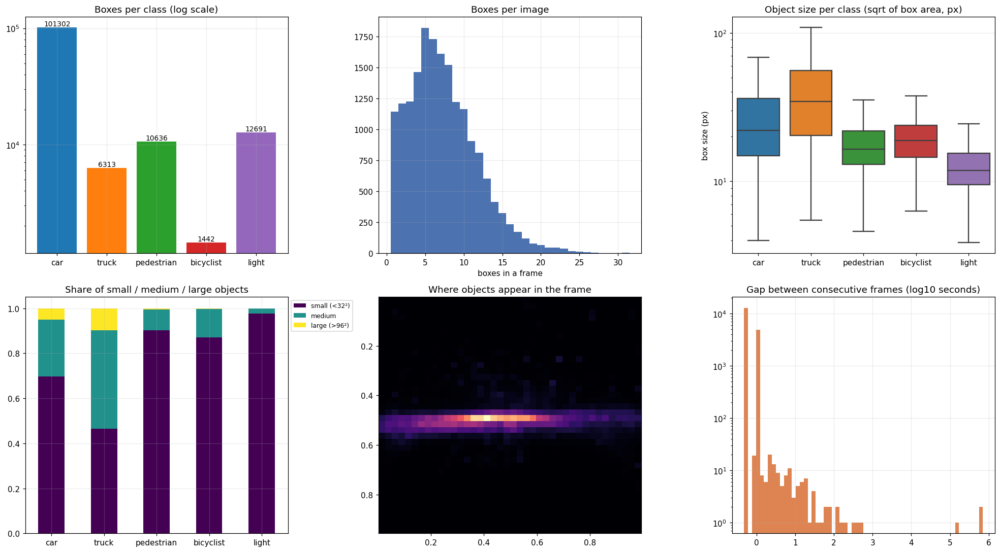

Objects per frame: mean 7.4, max 31
Share of 'small' objects (< 32x32 px): 73.1%
Class imbalance: most common / rarest = 70x
Median box: 22 x 20 px in a 480x300 image


In [6]:
# ---- 6. Exploratory data analysis ----
df["bw"], df["bh"] = df.xmax - df.xmin, df.ymax - df.ymin
df["area"] = df.bw * df.bh
df["side"] = np.sqrt(df.area)
bucket = pd.cut(df.area, [0, 32 ** 2, 96 ** 2, np.inf], labels=["small (<32²)", "medium", "large (>96²)"])

fig, ax = plt.subplots(2, 3, figsize=(18, 10))
cc = df.cname.value_counts().reindex(CLASS_NAMES)
ax[0, 0].bar(cc.index, cc.values, color=sns.color_palette("tab10", K))
ax[0, 0].set_yscale("log"); ax[0, 0].set_title("Boxes per class (log scale)")
for i, v in enumerate(cc.values):
    ax[0, 0].text(i, v, "%d" % v, ha="center", va="bottom", fontsize=9)

ax[0, 1].hist(FR.n_boxes, bins=np.arange(1, FR.n_boxes.max() + 2) - 0.5, color="#4c72b0")
ax[0, 1].set_title("Boxes per image"); ax[0, 1].set_xlabel("boxes in a frame")

sns.boxplot(data=df, x="cname", y="side", order=CLASS_NAMES, ax=ax[0, 2], showfliers=False)
ax[0, 2].set_yscale("log"); ax[0, 2].set_title("Object size per class (sqrt of box area, px)")
ax[0, 2].set_xlabel(""); ax[0, 2].set_ylabel("box size (px)")

ct = pd.crosstab(df.cname, bucket, normalize="index").reindex(CLASS_NAMES)
ct.plot(kind="bar", stacked=True, ax=ax[1, 0], colormap="viridis")
ax[1, 0].set_title("Share of small / medium / large objects"); ax[1, 0].set_xlabel("")
ax[1, 0].tick_params(axis="x", rotation=0); ax[1, 0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8)

cx, cy = (df.xmin + df.xmax) / 2 / df.w, (df.ymin + df.ymax) / 2 / df.h
ax[1, 1].hist2d(cx, cy, bins=40, cmap="magma")
ax[1, 1].invert_yaxis(); ax[1, 1].set_title("Where objects appear in the frame"); ax[1, 1].grid(False)

gaps = np.diff(FR.ts.values) / 1e9 if FR.ts.max() > 1e12 else np.diff(FR.ts.values)
ax[1, 2].hist(np.log10(np.maximum(gaps, 1e-3)), bins=60, color="#dd8452"); ax[1, 2].set_yscale("log")
ax[1, 2].set_title("Gap between consecutive frames (log10 seconds)")
plt.tight_layout(); plt.savefig(RES / "eda_overview.png", dpi=130); plt.show()

small_share = float((df.area < 32 ** 2).mean())
print("Objects per frame: mean %.1f, max %d" % (FR.n_boxes.mean(), FR.n_boxes.max()))
print("Share of 'small' objects (< 32x32 px): %.1f%%" % (100 * small_share))
print("Class imbalance: most common / rarest = %.0fx" % (cc.max() / max(cc.min(), 1)))
print("Median box: %.0f x %.0f px in a %dx%d image" % (df.bw.median(), df.bh.median(), FR.w.median(), FR.h.median()))

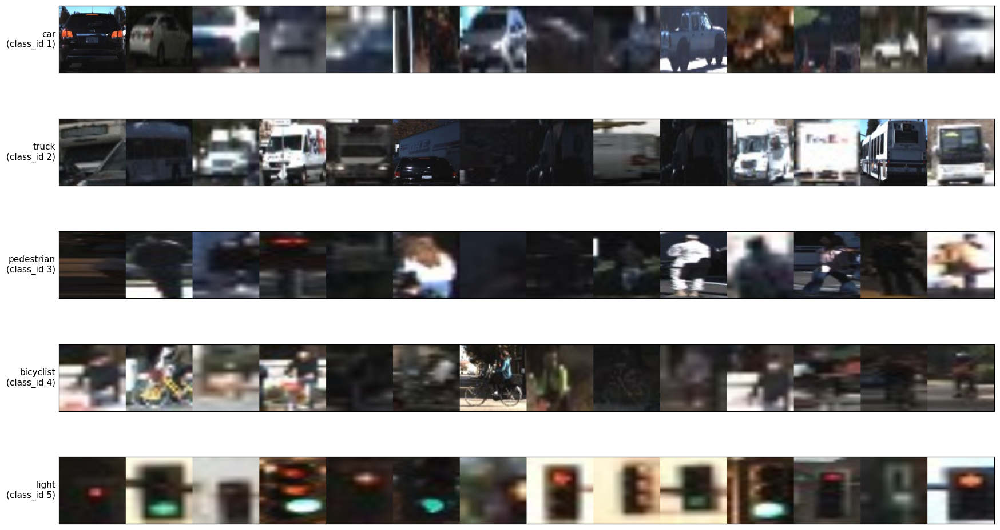

If a row does not show what its name says, correct CLASS_NAMES in the config cell and re-run.


In [7]:
# ---- 7. Verify the class-id -> class-name mapping visually (random crops of every class) ----
import cv2
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(K, 1, figsize=(16, 1.9 * K))
axes = np.atleast_1d(axes)
for k, ax in zip(range(K), axes):
    sub = df[(df.cls == k) & (df.bw >= 8) & (df.bh >= 8)]
    sub = sub.iloc[rng.permutation(len(sub))[:14]]
    crops = []
    for r in sub.itertuples():
        im = cv2.imread(r.path)
        crop = im[int(r.ymin):int(r.ymax), int(r.xmin):int(r.xmax)]
        crops.append(cv2.cvtColor(cv2.resize(crop, (96, 96)), cv2.COLOR_BGR2RGB))
    ax.imshow(np.hstack(crops) if crops else np.zeros((96, 96, 3), np.uint8))
    ax.set_yticks([]); ax.set_xticks([]); ax.grid(False)
    ax.set_ylabel("%s\n(class_id %d)" % (CLASS_NAMES[k], uniq[k]), rotation=0, ha="right", va="center")
plt.tight_layout(); plt.savefig(RES / "class_gallery.png", dpi=120); plt.show()
print("If a row does not show what its name says, correct CLASS_NAMES in the config cell and re-run.")

<a class="anchor" id="sec3"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">3 · Leakage-free split and export</p>

The split is by **contiguous blocks of time** (see the methodology). Out of many random block assignments, the one whose class distribution is closest to the 70 / 15 / 15 target is kept, and a few frames at every block edge are trimmed. Checks confirm that no frame appears in two splits and report how far apart in time the closest train and test frames are. Everything the models see comes from the files exported here (YOLO-format folders, annotation table and configuration).

blocks: 40 | trimmed frames per block edge: 10 | class-balance score: 0.201
closest train/test frames are 21 frames apart in time; closest train/val: 21


,frames,boxes,car,truck,pedestrian,bicyclist,light
train,12040,91444,70387,4157,7078,903,8919
val,2580,17912,13426,853,1655,227,1751
test,2580,17957,13685,995,1657,205,1415


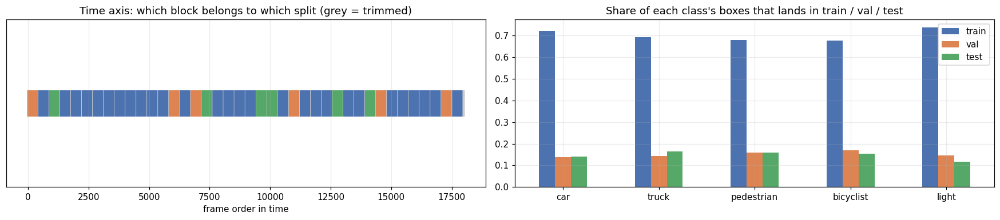

In [8]:
# ---- 8. Leakage-free, time-based split ----
# Frames are consecutive video frames -> neighbouring frames are almost identical.
# We therefore assign whole contiguous BLOCKS of time to train / val / test, trim a few frames at the
# edge of every block, and pick (out of many random block assignments) the one whose class
# distribution is closest to the target ratios in all three splits.
n = len(FR)
n_blocks = int(np.clip(n // 250, 8, 40))
edges = np.linspace(0, n, n_blocks + 1).astype(int)
blocks = [(int(edges[i]), int(edges[i + 1])) for i in range(n_blocks)]
GAP = int(max(2, min(10, (n // n_blocks) // 10)))

per_frame = pd.crosstab(df.frame, df.cls).reindex(index=FR.frame, columns=range(K), fill_value=0).to_numpy()
block_cls = np.stack([per_frame[a:b].sum(0) for a, b in blocks]).astype(float)
block_size = np.array([b - a for a, b in blocks])
split_names = list(SPLIT_RATIOS)
target = np.array([SPLIT_RATIOS[s] for s in split_names])

def try_assign(rng):
    order = rng.permutation(n_blocks)
    cur = np.zeros(len(split_names))
    assign = np.zeros(n_blocks, int)
    for b in order:
        s = int(np.argmax(target * n - cur))      # give the block to the split that is furthest below target
        assign[b] = s
        cur[s] += block_size[b]
    share = np.stack([block_cls[assign == s].sum(0) for s in range(len(split_names))])
    share = share / np.maximum(share.sum(0, keepdims=True), 1)
    return float(np.abs(share - target[:, None]).sum()), assign

best = min((try_assign(np.random.default_rng(SEED + t)) for t in range(600)), key=lambda x: x[0])
assign = best[1]
FR["split"] = "drop"
for (a, b), s in zip(blocks, assign):
    FR.loc[a + GAP:b - GAP - 1, "split"] = split_names[int(s)]
print("blocks: %d | trimmed frames per block edge: %d | class-balance score: %.3f" % (n_blocks, GAP, best[0]))

df = df.drop(columns=["split"], errors="ignore").merge(FR[["frame", "split"]], on="frame")
df = df[df.split != "drop"].reset_index(drop=True)

if FAST_DEV:                                     # tiny subset AFTER the split, so the split logic is still exercised
    rs = np.random.default_rng(SEED)
    keep = set()
    for s, nf in DEV_FRAMES.items():
        fs = sorted(df[df.split == s].frame.unique())
        keep |= set(rs.choice(fs, size=min(nf, len(fs)), replace=False))
    df = df[df.frame.isin(keep)].reset_index(drop=True)
    print("FAST_DEV: using only", {s: df[df.split == s].frame.nunique() for s in split_names}, "frames")

# ---- checks ----
fsets = {s: set(df[df.split == s].frame) for s in split_names}
assert not (fsets["train"] & fsets["val"]) and not (fsets["train"] & fsets["test"]) and not (fsets["val"] & fsets["test"]), "frame overlap!"
order_pos = {f: i for i, f in enumerate(FR.frame)}
def min_gap(a, b):
    pa = np.array(sorted(order_pos[f] for f in fsets[a])); pb = np.array(sorted(order_pos[f] for f in fsets[b]))
    return int(np.min(np.abs(pa[:, None] - pb[None, :]))) if len(pa) and len(pb) else -1
print("closest train/test frames are %d frames apart in time; closest train/val: %d" % (min_gap("train", "test"), min_gap("train", "val")))

summary = pd.DataFrame({s: {"frames": df[df.split == s].frame.nunique(), "boxes": int((df.split == s).sum()),
                            **{CLASS_NAMES[k]: int(((df.split == s) & (df.cls == k)).sum()) for k in range(K)}}
                        for s in split_names}).T
display(summary)

fig, ax = plt.subplots(1, 2, figsize=(16, 3.6))
colors = {"train": "#4c72b0", "val": "#dd8452", "test": "#55a868", "drop": "#cccccc"}
ax[0].scatter(np.arange(n), np.zeros(n), c=[colors[s] for s in FR.split], marker="|", s=900)
ax[0].set_yticks([]); ax[0].set_title("Time axis: which block belongs to which split (grey = trimmed)"); ax[0].set_xlabel("frame order in time")
share = summary[CLASS_NAMES].T
share = share / share.sum(1).values[:, None]
share.plot(kind="bar", ax=ax[1], color=[colors[s] for s in share.columns])
ax[1].set_title("Share of each class's boxes that lands in train / val / test")
ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(RES / "split_overview.png", dpi=130); plt.show()

In [9]:
# ---- 9. Export: YOLO-format dataset (also used by RF-DETR), annotation table, config for the scripts ----
from concurrent.futures import ThreadPoolExecutor

YOLO = DATA / "yolo"
SPLIT_DIR = {"train": "train", "val": "valid", "test": "test"}
samp = df.drop_duplicates("frame").path.sample(min(200, df.frame.nunique()), random_state=SEED)
avg_mb = np.mean([os.path.getsize(p) for p in samp]) / 1e6
est_gb = avg_mb * df.frame.nunique() / 1e3
USE_SYMLINK = est_gb > 12
print("estimated dataset copy size: %.1f GB -> %s" % (est_gb, "symlinks" if USE_SYMLINK else "copying files"))

jobs = []
for s, sd in SPLIT_DIR.items():
    (YOLO / sd / "images").mkdir(parents=True, exist_ok=True)
    (YOLO / sd / "labels").mkdir(parents=True, exist_ok=True)
    for f, g in df[df.split == s].groupby("frame"):
        stem = os.path.splitext(f)[0]
        lines = []
        W, H = float(g.w.iloc[0]), float(g.h.iloc[0])
        for r in g.itertuples():
            cx, cy = (r.xmin + r.xmax) / 2 / W, (r.ymin + r.ymax) / 2 / H
            lines.append("%d %.6f %.6f %.6f %.6f" % (r.cls, cx, cy, (r.xmax - r.xmin) / W, (r.ymax - r.ymin) / H))
        (YOLO / sd / "labels" / (stem + ".txt")).write_text("\n".join(lines))
        jobs.append((g.path.iloc[0], YOLO / sd / "images" / f))

def _put(a):
    src, dst = a
    if USE_SYMLINK:
        os.symlink(src, dst)
    else:
        shutil.copyfile(src, dst)
with ThreadPoolExecutor(16) as ex:
    list(ex.map(_put, jobs))

(YOLO / "data.yaml").write_text("path: %s\ntrain: train/images\nval: valid/images\ntest: test/images\nnames: %s\n"
                                % (YOLO, json.dumps(CLASS_NAMES)))

ann = df[["frame", "path", "xmin", "ymin", "xmax", "ymax", "cls", "split", "w", "h"]].copy()
ann.to_csv(OUT / "annotations.csv", index=False)

IMGSZ = int(min(640, math.ceil(max(FR.w.median(), FR.h.median()) / 32) * 32))
n_train = df[df.split == "train"].frame.nunique()
sc = IMGSZ / max(FR.w.median(), FR.h.median())
cache_gb = n_train * FR.w.median() * FR.h.median() * 3 * sc * sc / 1e9
CFG = dict(class_names=CLASS_NAMES, imgsz=IMGSZ, dfine_size=IMGSZ, seed=SEED, workers=WORKERS,
           yolo_dir=str(YOLO), yolo_yaml=str(YOLO / "data.yaml"),
           yolo_cache=("ram" if cache_gb < 6 and not FAST_DEV else False),
           quick_val_frames=QUICK_VAL_FRAMES, fast_dev=FAST_DEV, models=MODELS, **BENCH)
(OUT / "cfg.json").write_text(json.dumps(CFG, indent=1))
print("exported %d images | network input size for YOLO / D-FINE: %d | yolo cache: %s" % (len(jobs), IMGSZ, CFG["yolo_cache"]))

estimated dataset copy size: 0.7 GB -> copying files
exported 17200 images | network input size for YOLO / D-FINE: 480 | yolo cache: ram


<a class="anchor" id="sec4"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">4 · Training scripts</p>

Each model family has its own small script (written to disk by the cells below). Every script can **train**, **predict** on the test split and **benchmark** latency, and writes its results to `outputs/`. They run as **separate processes**, so one failure never stops the others.

In [10]:
%%writefile /kaggle/working/outputs/scripts/common.py
# Shared helpers used by every training script AND by the notebook (evaluation).
import os, sys, json, time, random, math
from pathlib import Path
import numpy as np
import pandas as pd

WORK = Path(os.environ.get("WORK_DIR", "/kaggle/working"))
OUT = WORK / "outputs"
for _d in ("preds", "meta", "weights", "logs", "runs"):
    (OUT / _d).mkdir(parents=True, exist_ok=True)


def log(msg):
    print("## " + str(msg), flush=True)


def load_cfg():
    return json.loads((OUT / "cfg.json").read_text())


def load_table():
    return pd.read_csv(OUT / "annotations.csv")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except Exception:
        pass


def split_items(df, split):
    """[[frame, path], ...] for every labelled frame of a split (sorted, deterministic)."""
    sub = df[df.split == split].drop_duplicates("frame").sort_values("frame")
    return sub[["frame", "path"]].values.tolist()


def read_bgr(path):
    import cv2
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise IOError("cannot read image: %s" % path)
    return img


def update_meta(key, **kw):
    p = OUT / "meta" / ("%s.json" % key)
    d = json.loads(p.read_text()) if p.exists() else {}
    d.update(kw)
    p.write_text(json.dumps(d, indent=1, default=str))
    return d


def read_meta(key):
    p = OUT / "meta" / ("%s.json" % key)
    return json.loads(p.read_text()) if p.exists() else {}


def finish():
    """Flush and leave immediately (avoids hangs caused by lingering worker threads)."""
    sys.stdout.flush()
    sys.stderr.flush()
    os._exit(0)


# --------------------------------------------------------------------------
# Predictions
# --------------------------------------------------------------------------
def run_predictions(items, predict_batch, bs=16, max_det=100):
    """predict_batch(list_of_bgr) -> list of (boxes_xyxy[N,4], scores[N], labels[N] in 0..K-1)."""
    preds = {}
    t0 = time.time()
    for i in range(0, len(items), bs):
        chunk = items[i:i + bs]
        imgs = [read_bgr(p) for _, p in chunk]
        outs = predict_batch(imgs)
        for (f, _), (b, s, l) in zip(chunk, outs):
            b = np.asarray(b, dtype=np.float32).reshape(-1, 4)
            s = np.asarray(s, dtype=np.float32).reshape(-1)
            l = np.asarray(l).astype(int).reshape(-1)
            if len(s) > max_det:
                o = np.argsort(-s)[:max_det]
                b, s, l = b[o], s[o], l[o]
            preds[f] = {"boxes": np.round(b, 1).tolist(),
                        "scores": np.round(s, 4).tolist(),
                        "labels": l.tolist()}
    return preds, time.time() - t0


def save_preds(key, preds):
    (OUT / "preds" / ("%s.json" % key)).write_text(json.dumps(preds))


def bench_latency(predict_one, bgr_images, warmup=20, iters=200):
    """End-to-end latency for ONE image at a time: BGR array in -> final detections out."""
    try:
        import torch
        sync = torch.cuda.synchronize if torch.cuda.is_available() else (lambda: None)
    except Exception:
        sync = lambda: None
    n = len(bgr_images)
    for i in range(warmup):
        predict_one(bgr_images[i % n])
    sync()
    ts = []
    for i in range(iters):
        im = bgr_images[i % n]
        sync()
        t = time.perf_counter()
        predict_one(im)
        sync()
        ts.append((time.perf_counter() - t) * 1000.0)
    ts = np.array(ts)
    return dict(mean_ms=float(ts.mean()), median_ms=float(np.median(ts)),
                p95_ms=float(np.percentile(ts, 95)), fps=float(1000.0 / ts.mean()),
                iters=int(iters))


# --------------------------------------------------------------------------
# Evaluation (one evaluator for ALL models -> fair comparison)
# --------------------------------------------------------------------------
def iou_matrix(a, b):
    a = np.asarray(a, dtype=np.float64).reshape(-1, 4)
    b = np.asarray(b, dtype=np.float64).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0])
    iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2])
    iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / np.maximum(aa[:, None] + ab[None, :] - inter, 1e-9)


def coco_eval(df, preds, class_names):
    """COCO-style bbox evaluation with pycocotools. df = annotation rows of ONE split."""
    import io, contextlib
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    K = len(class_names)
    frames = sorted(df.frame.unique())
    fid = {f: i + 1 for i, f in enumerate(frames)}
    dims = df.drop_duplicates("frame").set_index("frame")[["w", "h"]]
    images = [dict(id=fid[f], width=int(dims.loc[f, "w"]), height=int(dims.loc[f, "h"])) for f in frames]
    anns = []
    for i, r in enumerate(df.itertuples(index=False)):
        w, h = float(r.xmax - r.xmin), float(r.ymax - r.ymin)
        anns.append(dict(id=i + 1, image_id=fid[r.frame], category_id=int(r.cls) + 1,
                         bbox=[float(r.xmin), float(r.ymin), w, h], area=w * h, iscrowd=0))
    cats = [dict(id=k + 1, name=str(n)) for k, n in enumerate(class_names)]

    dets = []
    for f in frames:
        p = preds.get(f)
        if not p:
            continue
        for b, s, l in zip(p["boxes"], p["scores"], p["labels"]):
            l = int(l)
            if l < 0 or l >= K:
                continue
            dets.append(dict(image_id=fid[f], category_id=l + 1,
                             bbox=[float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])],
                             score=float(s)))
    nan = float("nan")
    empty = dict(AP=0.0, AP50=0.0, AP75=0.0, APs=nan, APm=nan, APl=nan, AR100=0.0,
                 per_class_AP={n: 0.0 for n in class_names}, per_class_AP50={n: 0.0 for n in class_names})
    if not dets:
        return empty

    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        gt = COCO()
        gt.dataset = dict(images=images, annotations=anns, categories=cats)
        gt.createIndex()
        dt = gt.loadRes(dets)
        E = COCOeval(gt, dt, "bbox")
        E.evaluate()
        E.accumulate()
        E.summarize()
    st = [float(x) if x >= 0 else nan for x in E.stats]
    prec = E.eval["precision"]          # [T, R, K, A, M]
    pc, pc50 = {}, {}
    for k, n in enumerate(class_names):
        p = prec[:, :, k, 0, 2]
        p = p[p > -1]
        pc[n] = float(p.mean()) if p.size else nan
        p5 = prec[0, :, k, 0, 2]
        p5 = p5[p5 > -1]
        pc50[n] = float(p5.mean()) if p5.size else nan
    return dict(AP=st[0], AP50=st[1], AP75=st[2], APs=st[3], APm=st[4], APl=st[5],
                AR100=st[8], per_class_AP=pc, per_class_AP50=pc50)


def prf_at(df, preds, K, conf=0.25, thr=0.5):
    """Precision / recall / F1 at one operating point (score >= conf, IoU >= thr, class-aware)."""
    tp = np.zeros(K)
    fp = np.zeros(K)
    fn = np.zeros(K)
    for f, sub in df.groupby("frame"):
        gb = sub[["xmin", "ymin", "xmax", "ymax"]].to_numpy(float)
        gc = sub["cls"].to_numpy(int)
        p = preds.get(f)
        if p and len(p["scores"]):
            pb = np.array(p["boxes"], float).reshape(-1, 4)
            ps = np.array(p["scores"], float)
            pcl = np.array(p["labels"], int)
            keep = ps >= conf
            pb, ps, pcl = pb[keep], ps[keep], pcl[keep]
            o = np.argsort(-ps)
            pb, pcl = pb[o], pcl[o]
        else:
            pb, pcl = np.zeros((0, 4)), np.zeros(0, int)
        for k in range(K):
            g = gb[gc == k]
            q = pb[pcl == k]
            if len(g) == 0:
                fp[k] += len(q)
                continue
            if len(q) == 0:
                fn[k] += len(g)
                continue
            iou = iou_matrix(q, g)
            used = np.zeros(len(g), bool)
            for i in range(len(q)):
                masked = np.where(used, -1.0, iou[i])
                j = int(masked.argmax())
                if masked[j] >= thr:
                    used[j] = True
                    tp[k] += 1
                else:
                    fp[k] += 1
            fn[k] += int((~used).sum())
    P = tp.sum() / max(tp.sum() + fp.sum(), 1)
    R = tp.sum() / max(tp.sum() + fn.sum(), 1)
    F1 = 2 * P * R / max(P + R, 1e-9)
    return dict(precision=float(P), recall=float(R), f1=float(F1))

Writing /kaggle/working/outputs/scripts/common.py


In [11]:
%%writefile /kaggle/working/outputs/scripts/train_yolo.py
# YOLOv8n / YOLO11n / YOLO11s (Ultralytics).  modes: train | predict | bench
import sys, os, time, argparse
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from common import *

ap = argparse.ArgumentParser()
ap.add_argument("--model", required=True)
ap.add_argument("--mode", default="train")
ap.add_argument("--amp", type=int, default=1)
ap.add_argument("--nocache", type=int, default=0)      # retry switch: train without the RAM image cache
args = ap.parse_args()

cfg = load_cfg()
mc = cfg["models"][args.model]
names = cfg["class_names"]
IMGSZ = cfg["imgsz"]
RUNS = OUT / "runs"


def best_weights():
    for n in ("best.pt", "last.pt"):
        p = RUNS / args.model / "weights" / n
        if p.exists():
            return p
    return None


if args.mode == "train":
    from ultralytics import YOLO
    set_seed(cfg["seed"])
    model = YOLO(mc["weights"])          # COCO-pretrained, downloaded automatically
    t0 = time.time()
    cap_s = mc["cap_min"] * 60
    state = {"epochs": 0}

    def _on_epoch_end(trainer):
        ep = int(trainer.epoch) + 1
        if ep > int(trainer.epochs):                 # Ultralytics fires this hook once more after the final evaluation
            return
        state["epochs"] = ep
        try:
            m = trainer.metrics
            log("epoch %d/%d  mAP50-95(val)=%.4f  mAP50(val)=%.4f  elapsed=%.1f min" % (
                ep, trainer.epochs, m.get("metrics/mAP50-95(B)", float("nan")),
                m.get("metrics/mAP50(B)", float("nan")), (time.time() - t0) / 60))
        except Exception:
            log("epoch %d finished" % ep)
        if time.time() - t0 > cap_s:
            log("time cap reached -> stopping training early")
            trainer.stop = True

    model.add_callback("on_fit_epoch_end", _on_epoch_end)
    model.train(data=str(cfg["yolo_yaml"]), epochs=mc["epochs"], imgsz=IMGSZ, batch=mc["batch"],
                workers=cfg["workers"], device=0, project=str(RUNS), name=args.model, exist_ok=True,
                seed=cfg["seed"], amp=bool(args.amp), cache=(False if args.nocache else cfg["yolo_cache"]), plots=True,
                patience=100, verbose=False)
    update_meta(args.model, train_minutes=(time.time() - t0) / 60, epochs_done=state["epochs"],
                epochs_planned=mc["epochs"], batch=mc["batch"], imgsz=IMGSZ,
                recipe="Ultralytics default (SGD/AdamW auto, mosaic, cosine-free linear LR), COCO-pretrained")
    finish()

# ---------------- predict / bench ----------------
from ultralytics import YOLO
w = best_weights()
if w is None:
    log("no trained weights found for %s" % args.model)
    sys.exit(2)
model = YOLO(str(w))


def predict_batch(imgs, conf=0.001):
    res = model.predict(source=imgs, imgsz=IMGSZ, conf=conf, iou=0.6, max_det=100,
                        verbose=False, half=False, device=0)
    return [(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int))
            for r in res]


def model_info():
    try:
        n_params = sum(p.numel() for p in model.model.parameters())
    except Exception:
        n_params = None
    gflops = None
    try:
        info = model.info(detailed=False, verbose=False, imgsz=IMGSZ)
        gflops = float(info[3])
    except Exception:
        pass
    return n_params, gflops


df = load_table()
if args.mode == "predict":
    items = split_items(df, "test")
    preds, sec = run_predictions(items, predict_batch, bs=16)
    save_preds(args.model, preds)
    n_params, gflops = model_info()
    update_meta(args.model, params_m=(n_params / 1e6 if n_params else None), gflops=gflops,
                input_size="%dx%d" % (IMGSZ, IMGSZ), nms=True, weights_used=str(w.name),
                predict_seconds=sec)
    log("predictions saved: %d test images in %.1fs" % (len(items), sec))
    finish()

if args.mode == "bench":
    items = split_items(df, "test")[: cfg["bench_images"]]
    imgs = [read_bgr(p) for _, p in items]
    r = bench_latency(lambda im: predict_batch([im], conf=0.25), imgs,
                      warmup=cfg["bench_warmup"], iters=cfg["bench_iters"])
    update_meta(args.model, bench=r)
    log("latency %.2f ms (%.1f FPS)" % (r["mean_ms"], r["fps"]))
    finish()

Writing /kaggle/working/outputs/scripts/train_yolo.py


In [12]:
%%writefile /kaggle/working/outputs/scripts/train_ssd.py
# SSD300-VGG16 and SSDlite320-MobileNetV3 (torchvision), fine-tuned from COCO weights.
# modes: train | predict | bench
import sys, os, time, math, argparse, random
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from common import *
import numpy as np
import cv2
import torch
from torch.utils.data import Dataset, DataLoader

ap = argparse.ArgumentParser()
ap.add_argument("--model", required=True)
ap.add_argument("--mode", default="train")
ap.add_argument("--amp", type=int, default=1)
args = ap.parse_args()

cfg = load_cfg()
mc = cfg["models"][args.model]
names = cfg["class_names"]
K = len(names)
KIND = mc["kind"]                      # "ssd300" or "ssdlite320"
SIZE = 300 if KIND == "ssd300" else 320
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WEIGHTS = OUT / "weights" / ("%s.pt" % args.model)


def build(pretrained):
    from functools import partial
    from torch import nn
    from torchvision.models.detection import _utils as det_utils
    from torchvision.models.detection.ssd import SSDClassificationHead
    from torchvision.models.detection.ssdlite import SSDLiteClassificationHead
    size = (SIZE, SIZE)
    if KIND == "ssd300":
        from torchvision.models.detection import ssd300_vgg16, SSD300_VGG16_Weights
        if pretrained:
            m = ssd300_vgg16(weights=SSD300_VGG16_Weights.COCO_V1)
            in_ch = det_utils.retrieve_out_channels(m.backbone, size)
            n_anchors = m.anchor_generator.num_anchors_per_location()
            m.head.classification_head = SSDClassificationHead(in_ch, n_anchors, K + 1)
        else:
            m = ssd300_vgg16(weights=None, weights_backbone=None, num_classes=K + 1)
    else:
        from torchvision.models.detection import (ssdlite320_mobilenet_v3_large,
                                                  SSDLite320_MobileNet_V3_Large_Weights)
        if pretrained:
            m = ssdlite320_mobilenet_v3_large(weights=SSDLite320_MobileNet_V3_Large_Weights.COCO_V1)
            in_ch = det_utils.retrieve_out_channels(m.backbone, size)
            n_anchors = m.anchor_generator.num_anchors_per_location()
            norm = partial(nn.BatchNorm2d, eps=0.001, momentum=0.03)
            m.head.classification_head = SSDLiteClassificationHead(in_ch, n_anchors, K + 1, norm)
        else:
            m = ssdlite320_mobilenet_v3_large(weights=None, weights_backbone=None, num_classes=K + 1)
    m.score_thresh = 0.001
    m.nms_thresh = 0.5
    m.detections_per_img = 100
    m.topk_candidates = 400
    return m


@torch.no_grad()
def predict_batch(model, imgs, conf=0.001):
    model.eval()
    model.score_thresh = conf
    tens = [torch.from_numpy(cv2.cvtColor(b, cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float().div_(255.0).to(dev)
            for b in imgs]
    out = model(tens)
    return [(o["boxes"].cpu().numpy(), o["scores"].cpu().numpy(), o["labels"].cpu().numpy() - 1) for o in out]


def n_params(model):
    return sum(p.numel() for p in model.parameters())


df = load_table()

if args.mode == "train":
    set_seed(cfg["seed"])

    class DetDS(Dataset):
        def __init__(self, d, train):
            self.train = train
            self.items = []
            for f, sub in d.groupby("frame", sort=True):
                self.items.append((sub.path.iloc[0],
                                   sub[["xmin", "ymin", "xmax", "ymax"]].to_numpy(np.float32),
                                   sub["cls"].to_numpy(np.int64) + 1))

        def __len__(self):
            return len(self.items)

        def __getitem__(self, i):
            path, boxes, labels = self.items[i]
            img = cv2.cvtColor(cv2.imread(path, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
            boxes = boxes.copy()
            if self.train:
                if random.random() < 0.5:                      # horizontal flip
                    img = img[:, ::-1]
                    wd = img.shape[1]
                    boxes[:, [0, 2]] = wd - boxes[:, [2, 0]]
                if random.random() < 0.5:                      # brightness / contrast jitter
                    a, b = random.uniform(0.75, 1.25), random.uniform(-20, 20)
                    img = np.clip(img.astype(np.float32) * a + b, 0, 255).astype(np.uint8)
            t = torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1).float().div_(255.0)
            return t, {"boxes": torch.from_numpy(boxes), "labels": torch.from_numpy(labels)}

    def collate(batch):
        return tuple(zip(*batch))

    train_df = df[df.split == "train"]
    val_items = split_items(df, "val")
    step = max(1, len(val_items) // cfg["quick_val_frames"])
    val_sub = val_items[::step][: cfg["quick_val_frames"]]
    val_df = df[(df.split == "val") & df.frame.isin({f for f, _ in val_sub})]

    loader = DataLoader(DetDS(train_df, True), batch_size=mc["batch"], shuffle=True, drop_last=True,
                        num_workers=cfg["workers"], collate_fn=collate, pin_memory=True,
                        persistent_workers=cfg["workers"] > 0)
    model = build(pretrained=True).to(dev)
    bb = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith("backbone")]
    hd = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith("backbone")]
    opt = torch.optim.AdamW([{"params": bb, "lr": mc["lr_backbone"]}, {"params": hd, "lr": mc["lr_head"]}],
                            weight_decay=1e-4)
    total_it = max(1, mc["epochs"] * len(loader))
    warm = max(1, min(300, total_it // 10))

    def lr_lambda(it):
        if it < warm:
            return (it + 1) / warm
        prog = (it - warm) / max(1, total_it - warm)
        return 0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * min(1.0, prog)))

    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    amp = bool(args.amp) and dev.type == "cuda"
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=amp)
    except Exception:
        scaler = torch.cuda.amp.GradScaler(enabled=amp)

    t0 = time.time()
    cap_s = mc["cap_min"] * 60
    best, history, bad = -1.0, [], 0
    log("%s: %d train frames, %d iters/epoch, %.1fM params" % (args.model, len(loader.dataset), len(loader),
                                                             n_params(model) / 1e6))
    for ep in range(mc["epochs"]):
        model.train()
        run_loss, nb = 0.0, 0
        for imgs, targets in loader:
            imgs = [i.to(dev, non_blocking=True) for i in imgs]
            targets = [{k: v.to(dev) for k, v in t.items()} for t in targets]
            with torch.autocast("cuda", enabled=amp):
                loss_dict = model(imgs, targets)
                loss = sum(loss_dict.values())
            if not torch.isfinite(loss):
                bad += 1
                opt.zero_grad(set_to_none=True)
                if bad >= 20:
                    raise RuntimeError("NONFINITE loss (AMP unstable) - retry with --amp 0")
                continue
            bad = 0
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            run_loss += float(loss.item())
            nb += 1
        tr_loss = run_loss / max(nb, 1)
        # --- quick validation on a fixed subset of the VALIDATION split (model selection) ---
        try:
            vp, _ = run_predictions(val_sub, lambda im: predict_batch(model, im), bs=16)
            val_ap = float(coco_eval(val_df, vp, names)["AP"])
        except Exception as e:
            log("quick-val failed (%s) -> selecting by training loss" % str(e)[:80])
            val_ap = -tr_loss
        history.append(dict(epoch=ep + 1, train_loss=tr_loss, val_AP=val_ap))
        if val_ap > best or not WEIGHTS.exists():
            best = val_ap
            torch.save(model.state_dict(), WEIGHTS)
        log("epoch %d/%d  loss=%.4f  val mAP50-95=%.4f  best=%.4f  elapsed=%.1f min" % (
            ep + 1, mc["epochs"], tr_loss, val_ap, best, (time.time() - t0) / 60))
        update_meta(args.model, history=history)
        if time.time() - t0 > cap_s:
            log("time cap reached -> stopping training early")
            break
    update_meta(args.model, train_minutes=(time.time() - t0) / 60, epochs_done=len(history),
                epochs_planned=mc["epochs"], batch=mc["batch"], history=history, amp=amp,
                recipe="AdamW (head lr %g / backbone lr %g), cosine LR, flip+brightness aug, COCO-pretrained, new head"
                       % (mc["lr_head"], mc["lr_backbone"]))
    finish()

# ---------------- predict / bench ----------------
if not WEIGHTS.exists():
    log("no trained weights found for %s" % args.model)
    sys.exit(2)
model = build(pretrained=False)
model.load_state_dict(torch.load(WEIGHTS, map_location="cpu"))
model.to(dev).eval()

if args.mode == "predict":
    items = split_items(df, "test")
    preds, sec = run_predictions(items, lambda im: predict_batch(model, im), bs=16)
    save_preds(args.model, preds)
    update_meta(args.model, params_m=n_params(model) / 1e6, input_size="%dx%d (fixed)" % (SIZE, SIZE),
                nms=True, predict_seconds=sec)
    log("predictions saved: %d test images in %.1fs" % (len(items), sec))
    finish()

if args.mode == "bench":
    items = split_items(df, "test")[: cfg["bench_images"]]
    imgs = [read_bgr(p) for _, p in items]
    r = bench_latency(lambda im: predict_batch(model, [im], conf=0.25), imgs,
                      warmup=cfg["bench_warmup"], iters=cfg["bench_iters"])
    update_meta(args.model, bench=r)
    log("latency %.2f ms (%.1f FPS)" % (r["mean_ms"], r["fps"]))
    finish()

Writing /kaggle/working/outputs/scripts/train_ssd.py


In [13]:
%%writefile /kaggle/working/outputs/scripts/train_dfine.py
# D-FINE nano / small (Hugging Face transformers port), fine-tuned from COCO weights.
# modes: train | predict | bench
import sys, os, time, math, argparse, random
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from common import *
import numpy as np
import cv2
import torch
from torch.utils.data import Dataset, DataLoader

ap = argparse.ArgumentParser()
ap.add_argument("--model", required=True)
ap.add_argument("--mode", default="train")
ap.add_argument("--amp", type=int, default=1)
args = ap.parse_args()

cfg = load_cfg()
mc = cfg["models"][args.model]
names = cfg["class_names"]
K = len(names)
S = int(cfg["dfine_size"])                 # square network input
HF_ID = mc["hf_id"]
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WDIR = OUT / "weights" / args.model        # fine-tuned model is stored here (save_pretrained)

from transformers import DFineForObjectDetection, AutoImageProcessor


def load_norm(src):
    try:
        proc = AutoImageProcessor.from_pretrained(src)
        if bool(getattr(proc, "do_normalize", False)):
            return True, list(proc.image_mean), list(proc.image_std), proc
        return False, None, None, proc
    except Exception as e:
        log("image processor not loaded (%s) -> using plain 0-1 scaling" % str(e)[:80])
        return False, None, None, None


def make_prep(do_norm, mean, std):
    mean_t = torch.tensor(mean).view(3, 1, 1) if do_norm else None
    std_t = torch.tensor(std).view(3, 1, 1) if do_norm else None

    def prep_rgb(rgb):
        x = torch.from_numpy(np.ascontiguousarray(rgb)).permute(2, 0, 1).float().div_(255.0)
        if do_norm:
            x = (x - mean_t) / std_t
        return x

    def prep_bgr(bgr):
        rgb = cv2.cvtColor(cv2.resize(bgr, (S, S), interpolation=cv2.INTER_LINEAR), cv2.COLOR_BGR2RGB)
        return prep_rgb(rgb)

    return prep_rgb, prep_bgr


@torch.no_grad()
def predict_batch(model, prep_bgr, imgs, conf=0.001, topk=100):
    model.eval()
    x = torch.stack([prep_bgr(b) for b in imgs]).to(dev)
    out = model(pixel_values=x)
    prob = out.logits.float().sigmoid()                      # [B, Q, C]
    boxes = out.pred_boxes.float()                           # [B, Q, 4] normalised cx, cy, w, h
    B, Q, C = prob.shape
    sc, idx = prob.reshape(B, -1).topk(min(topk, Q * C), dim=1)
    q = torch.div(idx, C, rounding_mode="floor")
    c = idx % C
    bx = torch.gather(boxes, 1, q.unsqueeze(-1).expand(-1, -1, 4))
    cx, cy, w, h = bx.unbind(-1)
    xyxy = torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], dim=-1)
    res = []
    for i, b in enumerate(imgs):
        H, W = b.shape[:2]
        sc_i = torch.tensor([W, H, W, H], device=dev, dtype=torch.float32)
        bb = xyxy[i] * sc_i
        bb[:, 0::2] = bb[:, 0::2].clamp(0, W)
        bb[:, 1::2] = bb[:, 1::2].clamp(0, H)
        keep = sc[i] >= conf
        res.append((bb[keep].cpu().numpy(), sc[i][keep].cpu().numpy(), c[i][keep].cpu().numpy()))
    return res


def n_params(model):
    return sum(p.numel() for p in model.parameters())


df = load_table()

if args.mode == "train":
    set_seed(cfg["seed"])
    do_norm, mean, std, proc = load_norm(HF_ID)
    prep_rgb, prep_bgr = make_prep(do_norm, mean, std)
    update_meta(args.model, norm=dict(do=bool(do_norm), mean=mean, std=std))

    class DS(Dataset):
        def __init__(self, d, train):
            self.train = train
            self.items = []
            for f, sub in d.groupby("frame", sort=True):
                self.items.append((sub.path.iloc[0],
                                   sub[["xmin", "ymin", "xmax", "ymax"]].to_numpy(np.float32),
                                   sub["cls"].to_numpy(np.int64),
                                   float(sub.w.iloc[0]), float(sub.h.iloc[0])))

        def __len__(self):
            return len(self.items)

        def __getitem__(self, i):
            path, boxes, labels, W, H = self.items[i]
            img = cv2.resize(cv2.imread(path, cv2.IMREAD_COLOR), (S, S), interpolation=cv2.INTER_LINEAR)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            cx = (boxes[:, 0] + boxes[:, 2]) / 2 / W
            cy = (boxes[:, 1] + boxes[:, 3]) / 2 / H
            bw = (boxes[:, 2] - boxes[:, 0]) / W
            bh = (boxes[:, 3] - boxes[:, 1]) / H
            if self.train:
                if random.random() < 0.5:
                    img = img[:, ::-1]
                    cx = 1.0 - cx
                if random.random() < 0.5:
                    a, b = random.uniform(0.75, 1.25), random.uniform(-20, 20)
                    img = np.clip(img.astype(np.float32) * a + b, 0, 255).astype(np.uint8)
            nb = np.stack([cx, cy, bw, bh], 1).astype(np.float32).clip(0.0, 1.0)
            ok = (nb[:, 2] > 1e-4) & (nb[:, 3] > 1e-4)
            return prep_rgb(img), {"class_labels": torch.from_numpy(labels[ok]), "boxes": torch.from_numpy(nb[ok])}

    def collate(batch):
        return torch.stack([b[0] for b in batch]), [b[1] for b in batch]

    train_df = df[df.split == "train"]
    val_items = split_items(df, "val")
    step = max(1, len(val_items) // cfg["quick_val_frames"])
    val_sub = val_items[::step][: cfg["quick_val_frames"]]
    val_df = df[(df.split == "val") & df.frame.isin({f for f, _ in val_sub})]

    id2label = {i: n for i, n in enumerate(names)}
    label2id = {n: i for i, n in id2label.items()}
    model = DFineForObjectDetection.from_pretrained(HF_ID, id2label=id2label, label2id=label2id,
                                                    ignore_mismatched_sizes=True).to(dev)
    assert model.config.num_labels == K, "num_labels mismatch: %s vs %s" % (model.config.num_labels, K)

    loader = DataLoader(DS(train_df, True), batch_size=mc["batch"], shuffle=True, drop_last=True,
                        num_workers=cfg["workers"], collate_fn=collate, pin_memory=True,
                        persistent_workers=cfg["workers"] > 0)
    bb = [p for n, p in model.named_parameters() if p.requires_grad and "backbone" in n]
    hd = [p for n, p in model.named_parameters() if p.requires_grad and "backbone" not in n]
    opt = torch.optim.AdamW([{"params": bb, "lr": mc["lr_backbone"]}, {"params": hd, "lr": mc["lr"]}],
                            weight_decay=1e-4)
    accum = mc["accum"]
    total_it = max(1, mc["epochs"] * (len(loader) // accum))
    warm = max(1, min(300, total_it // 10))

    def lr_lambda(it):
        if it < warm:
            return (it + 1) / warm
        prog = (it - warm) / max(1, total_it - warm)
        return 0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * min(1.0, prog)))

    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    amp = bool(args.amp) and dev.type == "cuda"
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=amp)
    except Exception:
        scaler = torch.cuda.amp.GradScaler(enabled=amp)

    t0 = time.time()
    cap_s = mc["cap_min"] * 60
    best, history, bad = -1e9, [], 0
    log("%s: %d train frames, %d iters/epoch, %.1fM params, input %dx%d" % (
        args.model, len(loader.dataset), len(loader), n_params(model) / 1e6, S, S))
    for ep in range(mc["epochs"]):
        model.train()
        run_loss, nb = 0.0, 0
        opt.zero_grad(set_to_none=True)
        for it, (x, labels) in enumerate(loader):
            x = x.to(dev, non_blocking=True)
            labels = [{k: v.to(dev) for k, v in t.items()} for t in labels]
            with torch.autocast("cuda", enabled=amp):
                out = model(pixel_values=x, labels=labels)
                loss = out.loss
            if not torch.isfinite(loss):
                bad += 1
                opt.zero_grad(set_to_none=True)
                if bad >= 20:
                    raise RuntimeError("NONFINITE loss (AMP unstable) - retry with --amp 0")
                continue
            bad = 0
            scaler.scale(loss / accum).backward()
            run_loss += float(loss.item())
            nb += 1
            if (it + 1) % accum == 0:
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 0.1)
                scaler.step(opt)
                scaler.update()
                opt.zero_grad(set_to_none=True)
                sched.step()
        tr_loss = run_loss / max(nb, 1)
        try:
            vp, _ = run_predictions(val_sub, lambda im: predict_batch(model, prep_bgr, im), bs=16)
            val_ap = float(coco_eval(val_df, vp, names)["AP"])
        except Exception as e:
            log("quick-val failed (%s) -> selecting by training loss" % str(e)[:80])
            val_ap = -tr_loss
        history.append(dict(epoch=ep + 1, train_loss=tr_loss, val_AP=val_ap))
        if val_ap > best or not WDIR.exists():
            best = val_ap
            model.save_pretrained(str(WDIR))
            if proc is not None:
                try:
                    proc.save_pretrained(str(WDIR))
                except Exception:
                    pass
        log("epoch %d/%d  loss=%.4f  val mAP50-95=%.4f  best=%.4f  elapsed=%.1f min" % (
            ep + 1, mc["epochs"], tr_loss, val_ap, best, (time.time() - t0) / 60))
        update_meta(args.model, history=history)
        if time.time() - t0 > cap_s:
            log("time cap reached -> stopping training early")
            break
    update_meta(args.model, train_minutes=(time.time() - t0) / 60, epochs_done=len(history),
                epochs_planned=mc["epochs"], batch=mc["batch"] * accum, history=history, amp=amp,
                recipe="AdamW (lr %g / backbone %g), cosine LR, grad-clip 0.1, flip+brightness aug, COCO-pretrained"
                       % (mc["lr"], mc["lr_backbone"]))
    finish()

# ---------------- predict / bench ----------------
if not WDIR.exists():
    log("no trained weights found for %s" % args.model)
    sys.exit(2)
_nm = read_meta(args.model).get("norm", {})
do_norm, mean, std = bool(_nm.get("do", False)), _nm.get("mean"), _nm.get("std")
prep_rgb, prep_bgr = make_prep(do_norm, mean, std)
model = DFineForObjectDetection.from_pretrained(str(WDIR)).to(dev).eval()

if args.mode == "predict":
    items = split_items(df, "test")
    preds, sec = run_predictions(items, lambda im: predict_batch(model, prep_bgr, im), bs=16)
    save_preds(args.model, preds)
    update_meta(args.model, params_m=n_params(model) / 1e6, input_size="%dx%d" % (S, S), nms=False,
                predict_seconds=sec)
    log("predictions saved: %d test images in %.1fs" % (len(items), sec))
    finish()

if args.mode == "bench":
    items = split_items(df, "test")[: cfg["bench_images"]]
    imgs = [read_bgr(p) for _, p in items]
    r = bench_latency(lambda im: predict_batch(model, prep_bgr, [im], conf=0.25), imgs,
                      warmup=cfg["bench_warmup"], iters=cfg["bench_iters"])
    update_meta(args.model, bench=r)
    log("latency %.2f ms (%.1f FPS)" % (r["mean_ms"], r["fps"]))
    finish()

Writing /kaggle/working/outputs/scripts/train_dfine.py


In [14]:
%%writefile /kaggle/working/outputs/scripts/train_rfdetr.py
# RF-DETR nano / small (Roboflow `rfdetr` package), fine-tuned from COCO weights.
# modes: train | predict | bench   (the notebook kills `train` when the time cap is reached,
# the best checkpoint written so far is then used by `predict`)
import sys, os, time, argparse
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from common import *
import numpy as np

ap = argparse.ArgumentParser()
ap.add_argument("--model", required=True)
ap.add_argument("--mode", default="train")
ap.add_argument("--amp", type=int, default=1)
args = ap.parse_args()

cfg = load_cfg()
mc = cfg["models"][args.model]
names = cfg["class_names"]
K = len(names)
RUN = OUT / "runs" / args.model


def get_cls():
    from rfdetr import RFDETRNano, RFDETRSmall
    return {"rfdetr_nano": RFDETRNano, "rfdetr_small": RFDETRSmall}[args.model]


def find_ckpt():
    for n in ("checkpoint_best_total.pth", "checkpoint_best_ema.pth", "checkpoint_best_regular.pth"):
        if (RUN / n).exists():
            return RUN / n
    c = sorted(RUN.glob("checkpoint*.pth"), key=lambda p: p.stat().st_mtime)
    if c:
        return c[-1]
    c = sorted(RUN.glob("*.ckpt"), key=lambda p: p.stat().st_mtime)
    return c[-1] if c else None


if args.mode == "train":
    set_seed(cfg["seed"])
    t0 = time.time()
    m = get_cls()()
    log("%s: training %d epochs (batch %d x accum %d)" % (args.model, mc["epochs"], mc["batch"], mc["accum"]))
    m.train(dataset_dir=str(cfg["yolo_dir"]), epochs=mc["epochs"], batch_size=mc["batch"],
            grad_accum_steps=mc["accum"], lr=mc["lr"], output_dir=str(RUN))
    update_meta(args.model, train_minutes=(time.time() - t0) / 60, epochs_done=mc["epochs"],
                epochs_planned=mc["epochs"], batch=mc["batch"] * mc["accum"],
                recipe="RF-DETR default recipe (AdamW, EMA, DINOv2 backbone), COCO-pretrained")
    finish()

# ---------------- predict / bench ----------------
from PIL import Image
import cv2

ck = find_ckpt()
if ck is None:
    log("no checkpoint found for %s" % args.model)
    sys.exit(2)
if ck.suffix == ".ckpt":
    from rfdetr import RFDETR
    m = RFDETR.from_checkpoint(str(ck))
else:
    m = get_cls()(pretrain_weights=str(ck))
log("loaded checkpoint %s" % ck.name)


def raw_predict(bgr, conf):
    pil = Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    d = m.predict(pil, threshold=conf)
    if isinstance(d, (list, tuple)):
        d = d[0]
    b = np.asarray(d.xyxy, dtype=np.float32).reshape(-1, 4)
    s = np.zeros(len(b), np.float32) if d.confidence is None else np.asarray(d.confidence, np.float32).reshape(-1)
    c = np.zeros(len(b), int) if d.class_id is None else np.asarray(d.class_id).astype(int).reshape(-1)
    return b, s, c


df = load_table()


def find_offset():
    """Class ids returned by RF-DETR may be shifted by one (COCO-style 1-based ids). Detect it."""
    try:
        cn = m.class_names
        if isinstance(cn, dict):
            inv = {str(v): int(k) for k, v in cn.items()}
            if all(n in inv for n in names):
                off = -inv[names[0]]
                if all(inv[n] + off == i for i, n in enumerate(names)):
                    return off, "from class names"
    except Exception:
        pass
    items = split_items(df, "val")
    sub = items[:: max(1, len(items) // 100)][:100]
    frames = {f for f, _ in sub}
    gt = {f: (g[["xmin", "ymin", "xmax", "ymax"]].to_numpy(float), g["cls"].to_numpy(int))
          for f, g in df[df.frame.isin(frames)].groupby("frame")}
    score = {0: 0, -1: 0, 1: 0}
    for f, p in sub:
        b, s, l = raw_predict(read_bgr(p), 0.3)
        if len(s) == 0 or f not in gt:
            continue
        gb, gc = gt[f]
        iou = iou_matrix(b, gb)
        for off in score:
            same = (l[:, None] + off) == gc[None, :]
            score[off] += int(((iou >= 0.5) & same).any(axis=1).sum())
    best = max(score.items(), key=lambda kv: (kv[1], kv[0] == 0))[0]
    return best, "IoU voting %s" % score


OFFSET, WHY = find_offset()
log("class-id offset = %d (%s)" % (OFFSET, WHY))


def predict_batch(imgs, conf=0.001):
    out = []
    for b in imgs:
        bx, sc, cl = raw_predict(b, conf)
        out.append((bx, sc, cl + OFFSET))
    return out


def count_params():
    try:
        return sum(p.numel() for p in m.model.model.parameters()) / 1e6
    except Exception:
        return None


def input_res():
    for getter in (lambda: m.model.resolution, lambda: m.model_config.resolution):
        try:
            return int(getter())
        except Exception:
            continue
    return None


if args.mode == "predict":
    items = split_items(df, "test")
    preds, sec = run_predictions(items, predict_batch, bs=8)
    save_preds(args.model, preds)
    res = input_res()
    update_meta(args.model, params_m=count_params(), input_size=("%dx%d" % (res, res)) if res else "native",
                nms=False, class_offset=OFFSET, checkpoint=ck.name, predict_seconds=sec)
    log("predictions saved: %d test images in %.1fs" % (len(items), sec))
    finish()

if args.mode == "bench":
    items = split_items(df, "test")[: cfg["bench_images"]]
    imgs = [read_bgr(p) for _, p in items]
    r = bench_latency(lambda im: predict_batch([im], conf=0.25), imgs,
                      warmup=cfg["bench_warmup"], iters=cfg["bench_iters"])
    update_meta(args.model, bench=r)
    log("latency %.2f ms (%.1f FPS)" % (r["mean_ms"], r["fps"]))
    finish()

Writing /kaggle/working/outputs/scripts/train_rfdetr.py


<a class="anchor" id="sec5"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">5 · Train and predict with every model</p>

The two GPUs work through their queues **in parallel**. Each model has a time cap, and the whole run has a global deadline, so the notebook always finishes.

In [15]:
# ---- 11. Job runner: every model runs in its own process, so a crash can never take the notebook down ----
sys.path.insert(0, str(SCRIPTS))
import common                                    # shared helpers (evaluation etc.), written above

T_START = time.time()
DEADLINE = T_START + GLOBAL_DEADLINE_H * 3600
PRINT_LOCK = threading.Lock()
STATUS = {}

def say(msg):
    with PRINT_LOCK:
        print(msg, flush=True)

def run_job(key, mode, gpu, timeout, extra=()):
    cmd = [sys.executable, "-u", str(SCRIPTS / MODELS[key]["script"]), "--model", key, "--mode", mode, *extra]
    env = dict(os.environ, CUDA_VISIBLE_DEVICES=str(gpu), PYTHONUNBUFFERED="1", WORK_DIR=str(WORK),
               WANDB_MODE="disabled", WANDB_DISABLED="true", HF_HUB_DISABLE_PROGRESS_BARS="1",
               YOLO_AUTOINSTALL="False", TOKENIZERS_PARALLELISM="false", OMP_NUM_THREADS="2")
    log_path = LOGS / ("%s_%s.log" % (key, mode))
    t0 = time.time()
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, env=env, cwd=str(WORK),
                            start_new_session=True)
    tail = []

    def reader():
        last_beat = time.time()
        with open(log_path, "ab") as lf:
            for raw_line in iter(proc.stdout.readline, b""):
                lf.write(raw_line)
                parts = raw_line.decode("utf-8", "replace").replace("\r", "\n").strip().splitlines()
                if not parts:
                    continue
                line = parts[-1].strip()
                tail.append(line)
                if len(tail) > 80:
                    del tail[:40]
                if line.startswith("##"):
                    say("[%s] %s" % (key, line[2:].strip()))
                    last_beat = time.time()
                elif time.time() - last_beat > 600:               # heartbeat every 10 min for silent jobs
                    say("[%s] still running ... %s" % (key, line[:140]))
                    last_beat = time.time()

    th = threading.Thread(target=reader, daemon=True)
    th.start()
    timed_out = False
    try:
        proc.wait(timeout=max(60, timeout))
    except subprocess.TimeoutExpired:
        timed_out = True
        say("[%s:%s] time limit reached -> stopping the process" % (key, mode))
        try:
            os.killpg(proc.pid, signal.SIGTERM)
            proc.wait(timeout=30)
        except Exception:
            try:
                os.killpg(proc.pid, signal.SIGKILL)
            except Exception:
                pass
            proc.wait()
    th.join(timeout=15)
    rc = proc.returncode
    if rc != 0 and not timed_out:
        say("[%s:%s] FAILED (exit code %s). Last log lines:\n    %s" % (key, mode, rc, "\n    ".join(tail[-25:])))
    return dict(rc=rc, timed_out=timed_out, seconds=time.time() - t0, tail=list(tail))

def process_model(key, gpu):
    mc = MODELS[key]
    st = STATUS.setdefault(key, {})
    remaining = DEADLINE - time.time()
    if remaining < 25 * 60:
        st["status"] = "skipped (global time budget used up)"
        say("[%s] skipped: global time budget used up" % key)
        return
    cap = min(mc["cap_min"] * 60, remaining - 15 * 60)
    say("=== %s: training on GPU %d (time cap %.0f min) ===" % (mc["label"], gpu, cap / 60))
    timeout = cap + (600 if mc["self_cap"] else 0)         # scripts stop themselves; RF-DETR is stopped from outside
    r = run_job(key, "train", gpu, timeout)
    unstable = any("NONFINITE" in l for l in r["tail"])
    failed = r["rc"] != 0 and not r["timed_out"]
    if failed and mc["family"] in ("SSD", "D-FINE") and (unstable or r["seconds"] < 900):
        say("[%s] training failed (AMP unstable or early error) -> retrying once in full precision" % key)
        r = run_job(key, "train", gpu, timeout, extra=("--amp", "0"))
    elif failed and mc["family"] == "YOLO" and r["seconds"] < 900:
        say("[%s] training failed early -> retrying once without the RAM image cache" % key)
        r = run_job(key, "train", gpu, timeout, extra=("--nocache", "1"))
    st.update(train_rc=r["rc"], timed_out=r["timed_out"], train_seconds=r["seconds"])
    common.update_meta(key, truncated=bool(r["timed_out"]))
    r2 = run_job(key, "predict", gpu, 45 * 60)
    ok = (OUT / "preds" / ("%s.json" % key)).exists()
    if ok and r["rc"] == 0:
        st["status"] = "ok"
    elif ok:
        st["status"] = "trained with problems (used last checkpoint)" if not r["timed_out"] else "ok (time cap reached)"
    else:
        st["status"] = "FAILED"
    say("=== %s finished: %s (%.1f min) ===" % (mc["label"], st["status"], (r["seconds"] + r2["seconds"]) / 60))

def run_queue(keys, gpu):
    for key in keys:
        try:
            process_model(key, gpu)
        except Exception as e:                                 # never let one model stop the queue
            STATUS.setdefault(key, {})["status"] = "FAILED (%s)" % str(e)[:120]
            say("[%s] unexpected error: %s" % (key, e))

In [16]:
# ---- 12. Train + predict every model (the two GPUs work through their queues in parallel) ----
threads = [threading.Thread(target=run_queue, args=(q, gpu)) for gpu, q in enumerate(QUEUES)]
for t in threads:
    t.start()
for t in threads:
    t.join()
for k in MODELS:
    STATUS.setdefault(k, {"status": "not run (library missing or not selected)"})
(OUT / "status.json").write_text(json.dumps(STATUS, indent=1, default=str))
print("\nTraining + prediction finished after %.1f min" % ((time.time() - T_START) / 60))
display(pd.DataFrame({MODELS[k]["label"]: {"status": v.get("status"), "train min": round(v.get("train_seconds", 0) / 60, 1)}
                      for k, v in STATUS.items()}).T)

=== D-FINE nano: training on GPU 0 (time cap 90 min) ===
=== RF-DETR nano: training on GPU 1 (time cap 100 min) ===
[dfine_nano] dfine_nano: 12040 train frames, 1505 iters/epoch, 3.7M params, input 480x480
[rfdetr_nano] rfdetr_nano: training 10 epochs (batch 8 x accum 2)
[dfine_nano] epoch 1/10  loss=20.0294  val mAP50-95=0.1480  best=0.1480  elapsed=7.3 min
[dfine_nano] epoch 2/10  loss=15.2295  val mAP50-95=0.1667  best=0.1667  elapsed=14.8 min
[rfdetr_nano] still running ... Val (ema) (Epoch 2/10) — Overall Metrics
[dfine_nano] epoch 3/10  loss=14.8976  val mAP50-95=0.1781  best=0.1781  elapsed=22.3 min
[dfine_nano] epoch 4/10  loss=14.7237  val mAP50-95=0.1854  best=0.1854  elapsed=29.8 min
[dfine_nano] epoch 5/10  loss=14.6048  val mAP50-95=0.1873  best=0.1873  elapsed=37.3 min
[rfdetr_nano] still running ... Val (ema) (Epoch 4/10) — Overall Metrics
[dfine_nano] epoch 6/10  loss=14.5371  val mAP50-95=0.1905  best=0.1905  elapsed=44.7 min
[dfine_nano] epoch 7/10  loss=14.4811  val 

,status,train min
D-FINE nano,ok,75.6
RF-DETR nano,ok,97.1
YOLOv8n,ok,37.5
D-FINE small,ok,97.0
YOLO11n,ok,43.7
YOLO11s,ok,48.2
SSDlite320 (MNv3),ok,43.4
SSD300 (VGG16),ok,41.9
RF-DETR small,ok,122.3


<a class="anchor" id="sec6"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">6 · Speed benchmark</p>

Inference speed is measured for **one model at a time** on an idle GPU: batch size 1, FP32, from a raw BGR image to final detections (pre-processing and NMS included where a model needs it).

In [17]:
# ---- 13. Speed benchmark: one model at a time on an otherwise idle GPU (batch size 1, FP32, end-to-end) ----
BENCH_OK = []
for key in MODELS:
    if not (OUT / "preds" / ("%s.json" % key)).exists():
        continue
    if time.time() > DEADLINE + 20 * 60:
        say("[%s] benchmark skipped (time budget)" % key)
        continue
    r = run_job(key, "bench", 0, 15 * 60)
    if r["rc"] == 0:
        BENCH_OK.append(key)
print("benchmarked:", BENCH_OK)

[yolov8n] latency 8.05 ms (124.3 FPS)
[yolo11n] latency 10.11 ms (98.9 FPS)
[yolo11s] latency 10.24 ms (97.6 FPS)
[ssd300] latency 19.69 ms (50.8 FPS)
[ssdlite320] latency 16.65 ms (60.1 FPS)
[rfdetr_nano] loaded checkpoint checkpoint_best_total.pth
[rfdetr_nano] class-id offset = 0 (IoU voting {0: 500, -1: 9, 1: 13})
[rfdetr_nano] latency 20.09 ms (49.8 FPS)
[rfdetr_small] loaded checkpoint checkpoint_best_total.pth
[rfdetr_small] class-id offset = 0 (IoU voting {0: 559, -1: 10, 1: 18})
[rfdetr_small] latency 27.72 ms (36.1 FPS)
[dfine_nano] latency 30.22 ms (33.1 FPS)
[dfine_small] latency 33.92 ms (29.5 FPS)
benchmarked: ['yolov8n', 'yolo11n', 'yolo11s', 'ssd300', 'ssdlite320', 'rfdetr_nano', 'rfdetr_small', 'dfine_nano', 'dfine_small']


<a class="anchor" id="sec7"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">7 · Evaluation on the test split</p>

**One evaluator** (pycocotools) for every model. mAP is computed from all detections with score > 0.001 (max. 100 per image); precision / recall use a fixed score threshold of 0.25. The test split is used here for the first and only time.

In [18]:
# ---- 14. Evaluation of ALL models on the held-out TEST split with ONE evaluator ----
ann = pd.read_csv(OUT / "annotations.csv")
test_df = ann[ann.split == "test"]
rows, EVAL, PREDS = [], {}, {}
for key, mc in MODELS.items():
    pf = OUT / "preds" / ("%s.json" % key)
    if not pf.exists():
        continue
    preds = json.loads(pf.read_text())
    PREDS[key] = preds
    m = common.coco_eval(test_df, preds, CLASS_NAMES)
    prf = common.prf_at(test_df, preds, K, conf=0.25, thr=0.5)
    EVAL[key] = dict(coco=m, prf=prf)
    meta = common.read_meta(key)
    bench = meta.get("bench", {})
    rows.append({
        "key": key, "Model": mc["label"], "Family": mc["family"],
        "Params (M)": meta.get("params_m"), "Input": meta.get("input_size"),
        "Epochs": "%s/%s" % (meta.get("epochs_done", "?"), meta.get("epochs_planned", mc["epochs"])),
        "Train (min)": meta.get("train_minutes"),
        "mAP50-95": m["AP"], "mAP50": m["AP50"], "mAP75": m["AP75"],
        "AP small": m["APs"], "AP medium": m["APm"], "AP large": m["APl"], "AR@100": m["AR100"],
        "P@0.25": prf["precision"], "R@0.25": prf["recall"], "F1@0.25": prf["f1"],
        "Latency (ms)": bench.get("mean_ms"), "FPS": bench.get("fps"),
        "Real-time": (bench.get("fps", 0) or 0) >= REALTIME_FPS,
        "NMS": meta.get("nms"), "Truncated": meta.get("truncated", False),
    })
R = pd.DataFrame(rows)
if R.empty:
    raise RuntimeError("No model produced predictions - check the logs in %s" % LOGS)
R = R.sort_values("mAP50-95", ascending=False).reset_index(drop=True)
R.to_csv(RES / "results_table.csv", index=False)
show = ["Model", "Family", "Params (M)", "Input", "Epochs", "Train (min)", "mAP50-95", "mAP50", "AP small", "AP medium",
        "AP large", "P@0.25", "R@0.25", "Latency (ms)", "FPS", "Real-time"]
display(R[show].round(3))
print("Test split: %d frames, %d boxes. Real-time = at least %d FPS at batch size 1 on this GPU (T4)." % (
    test_df.frame.nunique(), len(test_df), REALTIME_FPS))

,Model,Family,Params (M),Input,Epochs,Train (min),mAP50-95,mAP50,AP small,AP medium,AP large,P@0.25,R@0.25,Latency (ms),FPS,Real-time
0,D-FINE small,D-FINE,10.213,480x480,10/10,96.565,0.280,0.531,0.231,0.380,0.861,0.308,0.852,33.918,29.483,False
1,YOLO11s,YOLO,9.430,480x480,25/25,48.126,0.269,0.516,0.218,0.408,0.532,0.774,0.710,10.242,97.636,True
2,RF-DETR small,RF-DETR,31.805,512x512,10/10,122.291,0.250,0.554,0.186,0.454,0.825,0.545,0.730,27.724,36.070,True
3,YOLOv8n,YOLO,3.139,480x480,25/25,37.392,0.239,0.468,0.186,0.335,0.764,0.775,0.676,8.046,124.283,True
4,YOLO11n,YOLO,2.606,480x480,25/25,43.580,0.222,0.434,0.171,0.322,0.566,0.741,0.657,10.114,98.873,True
5,D-FINE nano,D-FINE,3.722,480x480,10/10,75.287,0.209,0.409,0.152,0.336,0.799,0.275,0.767,30.219,33.092,True
6,RF-DETR nano,RF-DETR,30.161,384x384,10/10,97.035,0.209,0.484,0.144,0.376,0.680,0.517,0.666,20.088,49.782,True
7,SSD300 (VGG16),SSD,24.281,300x300 (fixed),10/10,41.459,0.174,0.368,0.126,0.286,0.479,0.764,0.574,19.689,50.791,True
8,SSDlite320 (MNv3),SSD,2.262,320x320 (fixed),20/20,43.048,0.073,0.162,0.023,0.181,0.739,0.477,0.394,16.651,60.056,True


Test split: 2580 frames, 17957 boxes. Real-time = at least 30 FPS at batch size 1 on this GPU (T4).


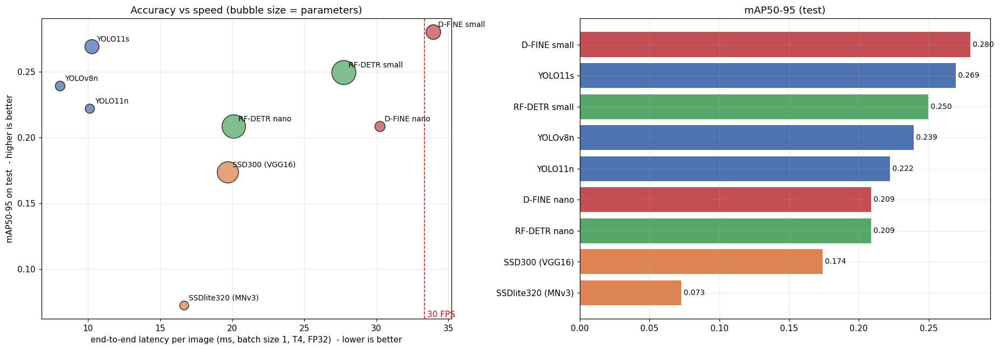

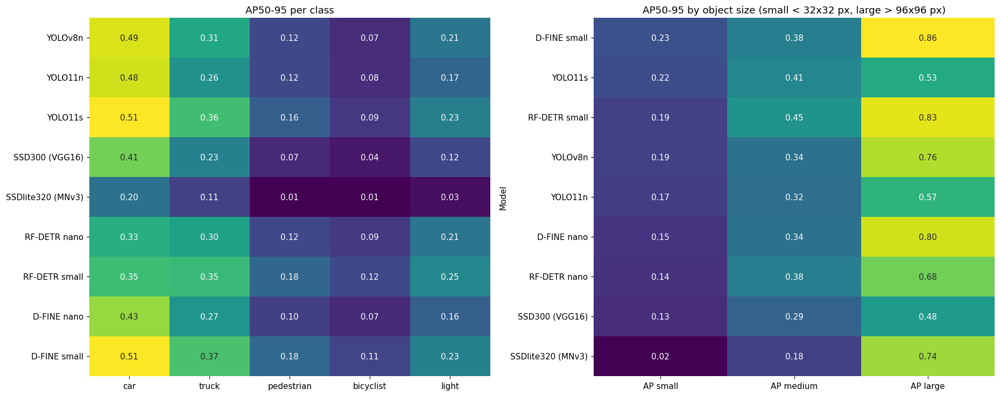

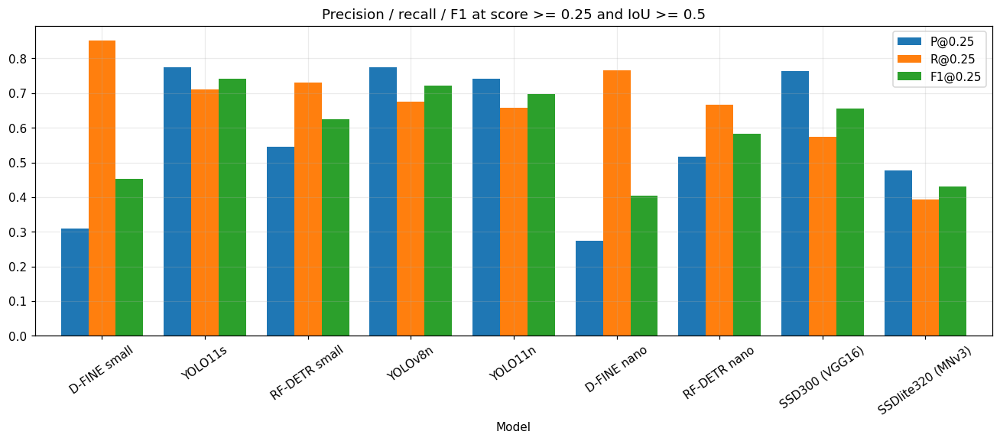

In [19]:
# ---- 15. Comparison plots ----
FAM_COL = {"YOLO": "#4c72b0", "SSD": "#dd8452", "RF-DETR": "#55a868", "D-FINE": "#c44e52"}
Rp = R.copy()

fig, ax = plt.subplots(1, 2, figsize=(17, 6))
# (a) accuracy vs speed
has_lat = Rp["Latency (ms)"].notna()
for _, r in Rp[has_lat].iterrows():
    x, y = r["Latency (ms)"], r["mAP50-95"]
    size = 60 + 25 * (r["Params (M)"] if pd.notna(r["Params (M)"]) else 3)
    ax[0].scatter(x, y, s=size, color=FAM_COL.get(r["Family"], "grey"), alpha=0.75, edgecolor="k")
    ax[0].annotate(r["Model"], (x, y), textcoords="offset points", xytext=(6, 6), fontsize=9)
ax[0].axvline(1000.0 / REALTIME_FPS, color="red", ls="--", lw=1)
ax[0].text(1000.0 / REALTIME_FPS, ax[0].get_ylim()[0], " %d FPS" % REALTIME_FPS, color="red", va="bottom")
ax[0].set_xlabel("end-to-end latency per image (ms, batch size 1, T4, FP32)  - lower is better")
ax[0].set_ylabel("mAP50-95 on test  - higher is better")
ax[0].set_title("Accuracy vs speed (bubble size = parameters)")
# (b) ranking
order = Rp.sort_values("mAP50-95")
ax[1].barh(order.Model, order["mAP50-95"], color=[FAM_COL.get(f, "grey") for f in order.Family])
for i, v in enumerate(order["mAP50-95"]):
    ax[1].text(v, i, " %.3f" % v, va="center", fontsize=9)
ax[1].set_title("mAP50-95 (test)")
plt.tight_layout(); plt.savefig(RES / "accuracy_vs_speed.png", dpi=130); plt.show()

# per-class AP and AP by size
fig, ax = plt.subplots(1, 2, figsize=(17, 5 + 0.2 * len(Rp)))
pc = pd.DataFrame({MODELS[k]["label"]: v["coco"]["per_class_AP"] for k, v in EVAL.items()}).T[CLASS_NAMES]
sns.heatmap(pc, annot=True, fmt=".2f", cmap="viridis", ax=ax[0], cbar=False)
ax[0].set_title("AP50-95 per class"); ax[0].grid(False)
sz = Rp.set_index("Model")[["AP small", "AP medium", "AP large"]]
sns.heatmap(sz, annot=True, fmt=".2f", cmap="viridis", ax=ax[1], cbar=False)
ax[1].set_title("AP50-95 by object size (small < 32x32 px, large > 96x96 px)"); ax[1].grid(False)
plt.tight_layout(); plt.savefig(RES / "per_class_and_size_ap.png", dpi=130); plt.show()

# operating point
fig, ax = plt.subplots(figsize=(12, 4 + 0.15 * len(Rp)))
Rp.set_index("Model")[["P@0.25", "R@0.25", "F1@0.25"]].plot(kind="bar", ax=ax, width=0.8)
ax.set_title("Precision / recall / F1 at score >= 0.25 and IoU >= 0.5"); ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.savefig(RES / "operating_point.png", dpi=130); plt.show()

<a class="anchor" id="sec8"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">8 · Visual comparison</p>

The **same test images** for every model. Colours are classes; only detections above the score threshold are drawn.

visualised test frames: 9 (2 crowded, pedestrians, bicyclist, truck, random)


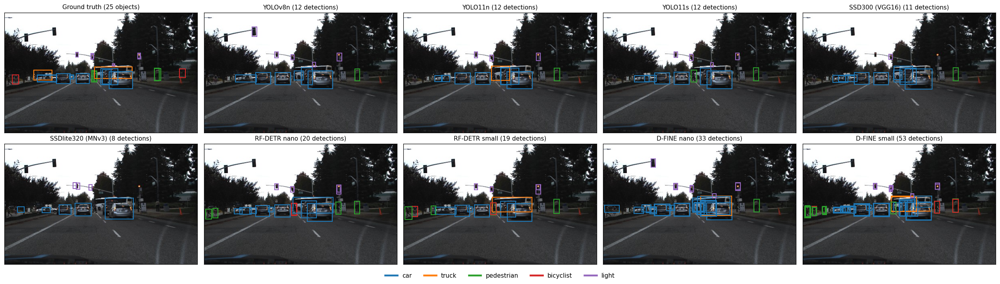

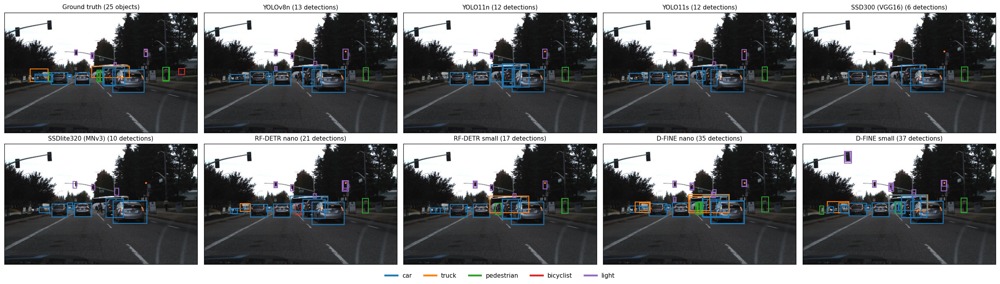

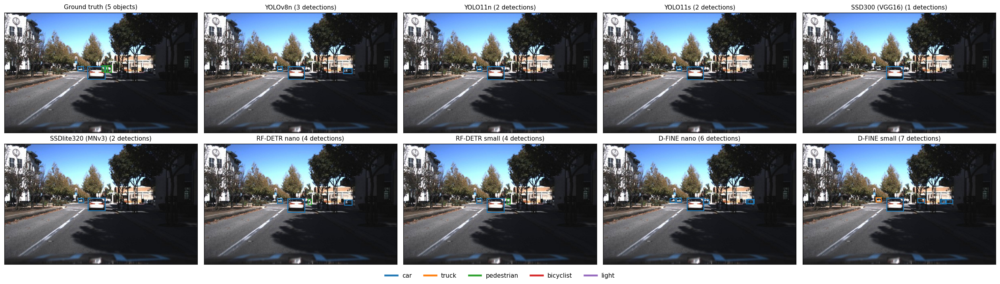

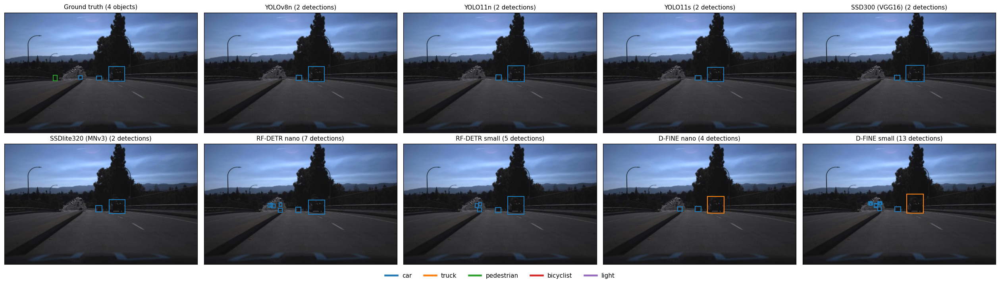

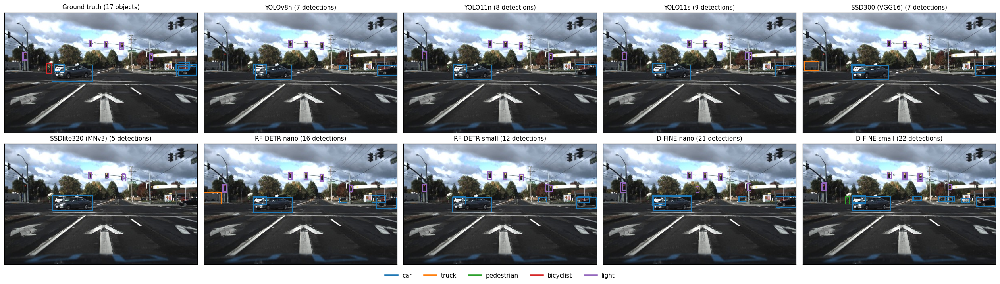

...

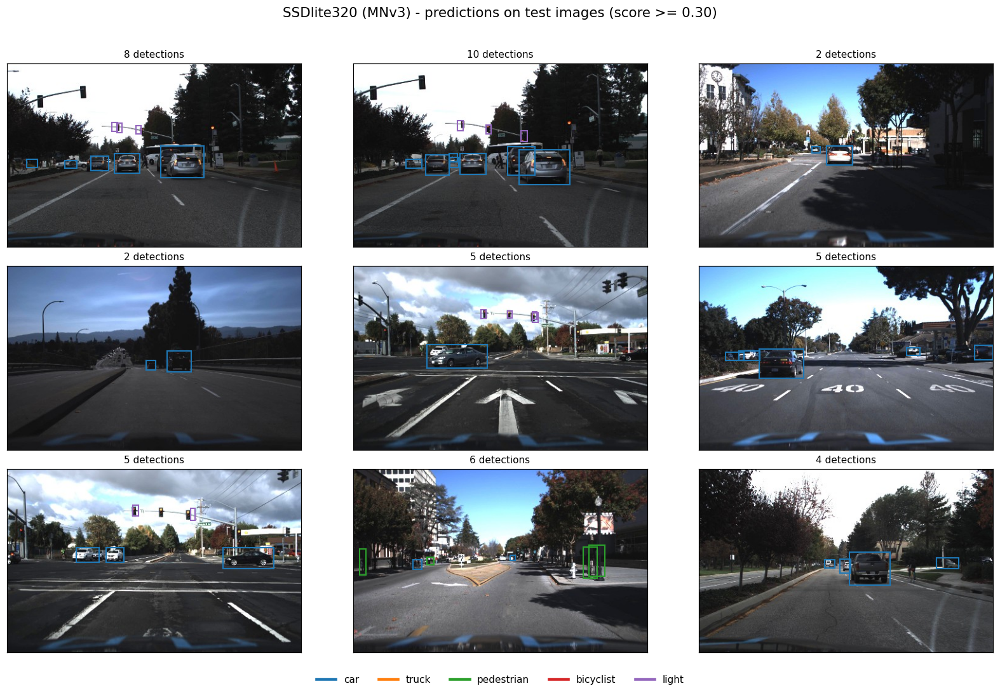

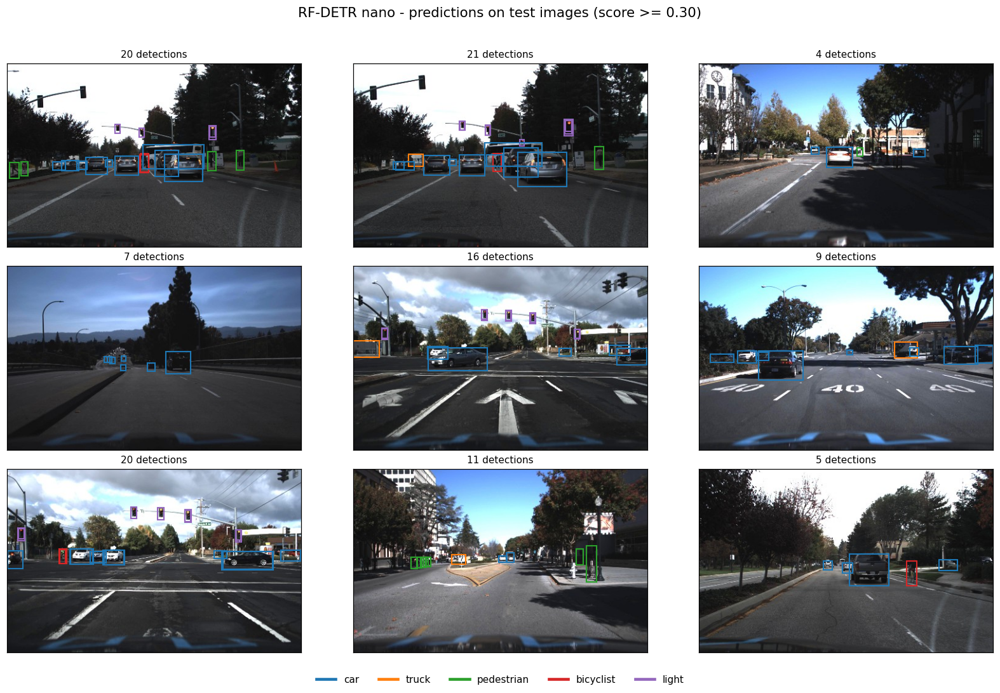

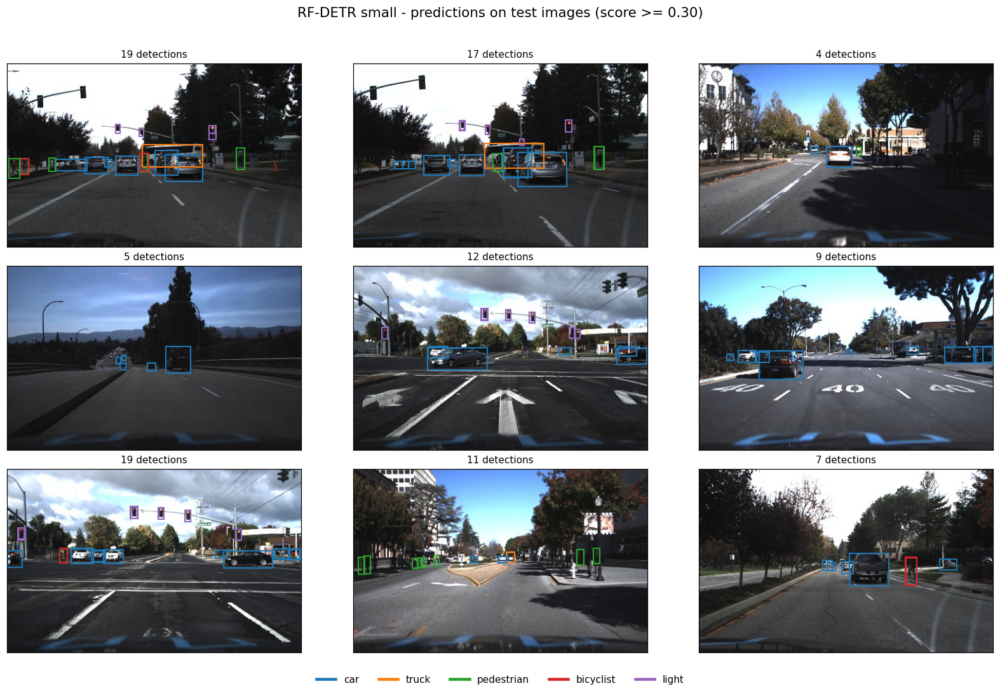

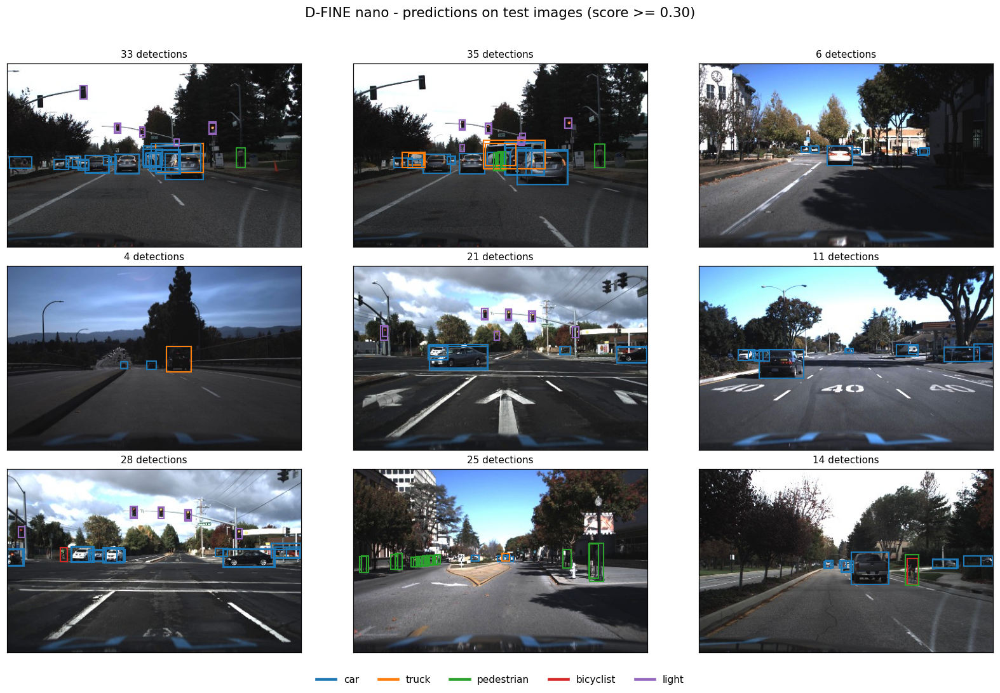

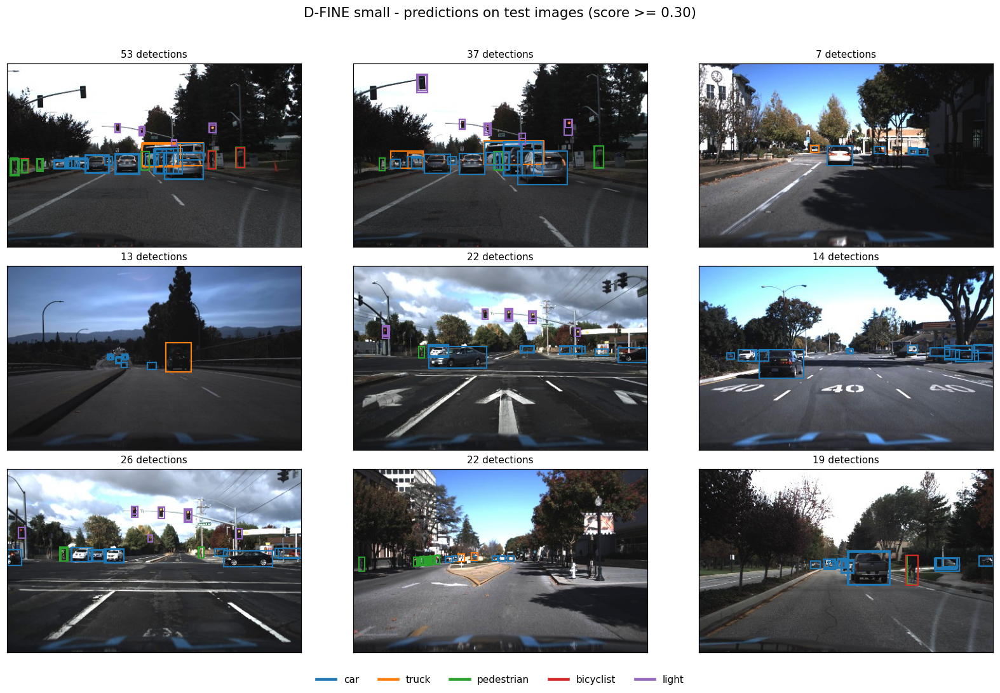

In [20]:
# ---- 16. Visual comparison: the SAME test images, every model's predictions ----
import cv2
K = len(CLASS_NAMES)
PALETTE = plt.cm.tab10(np.linspace(0, 1, 10))[:K]
path_of = ann.drop_duplicates("frame").set_index("frame").path.to_dict()
test_frames = sorted(test_df.frame.unique())
gt_of = {f: (g[["xmin", "ymin", "xmax", "ymax"]].to_numpy(), g.cls.to_numpy()) for f, g in test_df.groupby("frame")}

rs = np.random.default_rng(SEED + 1)
def pick(cond, n):
    pool = [f for f in test_frames if cond(gt_of[f])]
    return list(rs.choice(pool, size=min(n, len(pool)), replace=False)) if pool else []
crowded = sorted(test_frames, key=lambda f: -len(gt_of[f][1]))[:2]
sel = crowded + pick(lambda g: (g[1] == 2).any(), 2) + pick(lambda g: (g[1] == 3).any(), 1) \
      + pick(lambda g: (g[1] == 1).any(), 1) + pick(lambda g: True, 3)
VIS_FRAMES = list(dict.fromkeys(sel))[:9]
print("visualised test frames:", len(VIS_FRAMES), "(2 crowded, pedestrians, bicyclist, truck, random)")

def draw(ax, img, boxes, labels, title):
    ax.imshow(img); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for b, c in zip(boxes, labels):
        ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False,
                                   edgecolor=PALETTE[int(c) % K], linewidth=1.4))
    ax.set_title(title, fontsize=10)

def model_dets(key, f):
    p = PREDS[key].get(f)
    if not p:
        return np.zeros((0, 4)), np.zeros(0, int)
    s = np.array(p["scores"]); keep = s >= VIS_CONF
    return np.array(p["boxes"]).reshape(-1, 4)[keep], np.array(p["labels"], int)[keep]

legend = [plt.Line2D([0], [0], color=PALETTE[k], lw=3, label=CLASS_NAMES[k]) for k in range(K)]
keys = [k for k in MODELS if k in PREDS]

# (a) one figure per image: ground truth + all models side by side
for f in VIS_FRAMES[:6]:
    img = cv2.cvtColor(cv2.imread(path_of[f]), cv2.COLOR_BGR2RGB)
    panels = ["GT"] + keys
    ncols = 5; nrows = int(math.ceil(len(panels) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.2 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, p in zip(axes, panels):
        if p == "GT":
            draw(ax, img, gt_of[f][0], gt_of[f][1], "Ground truth (%d objects)" % len(gt_of[f][1]))
        else:
            b, l = model_dets(p, f)
            draw(ax, img, b, l, "%s (%d detections)" % (MODELS[p]["label"], len(l)))
    for ax in axes[len(panels):]:
        ax.axis("off")
    fig.legend(handles=legend, loc="lower center", ncol=K, frameon=False)
    plt.tight_layout(rect=(0, 0.04, 1, 1), h_pad=2.5); plt.savefig(RES / ("compare_%s.png" % f.split(".")[0]), dpi=110); plt.show()

# (b) one 3x3 grid per model on the same images
for key in keys:
    fig, axes = plt.subplots(3, 3, figsize=(15, 10))
    for ax, f in zip(axes.reshape(-1), VIS_FRAMES):
        img = cv2.cvtColor(cv2.imread(path_of[f]), cv2.COLOR_BGR2RGB)
        b, l = model_dets(key, f)
        draw(ax, img, b, l, "%d detections" % len(l))
    for ax in axes.reshape(-1)[len(VIS_FRAMES):]:
        ax.axis("off")
    fig.suptitle("%s - predictions on test images (score >= %.2f)" % (MODELS[key]["label"], VIS_CONF), fontsize=14)
    fig.legend(handles=legend, loc="lower center", ncol=K, frameon=False)
    plt.tight_layout(rect=(0, 0.04, 1, 0.96), h_pad=1.5); plt.savefig(RES / ("grid_%s.png" % key), dpi=110); plt.show()

<a class="anchor" id="sec9"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">9 · Training curves, summary and clean-up</p>

Validation mAP per epoch for every model (where the framework logs it), an automatic summary of the results, and clean-up of the output folder (best weights, predictions and results are kept).

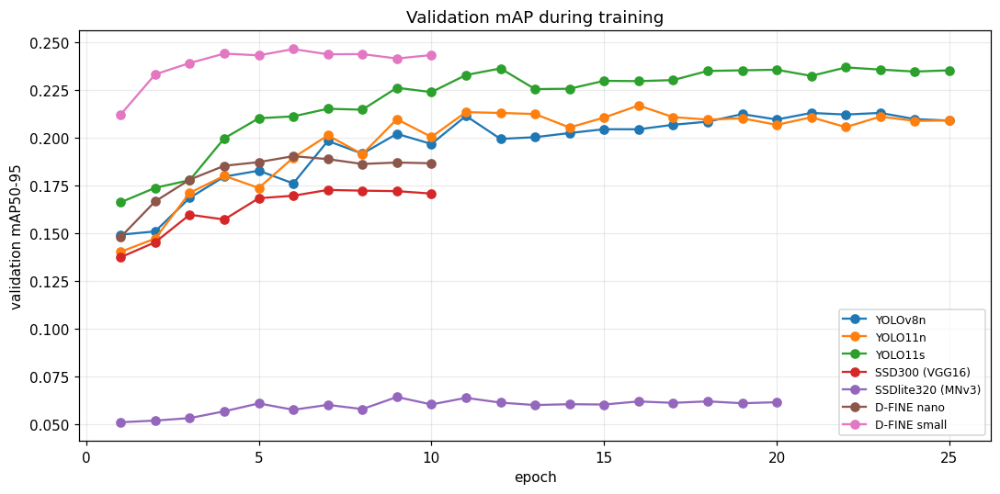

In [21]:
# ---- 17. Training curves (validation mAP per epoch, where the framework logs it) ----
fig, ax = plt.subplots(figsize=(10, 5)); plotted = 0
for key in MODELS:
    label = MODELS[key]["label"]
    csv = OUT / "runs" / key / "results.csv"                      # Ultralytics log
    try:
        if csv.exists():
            h = pd.read_csv(csv); h.columns = [c.strip() for c in h.columns]
            ax.plot(h["epoch"], h["metrics/mAP50-95(B)"], marker="o", label=label); plotted += 1
            continue
        hist = common.read_meta(key).get("history")
        if hist:
            ax.plot([x["epoch"] for x in hist], [x["val_AP"] for x in hist], marker="o", label=label); plotted += 1
    except Exception as e:
        print("curve skipped for", key, e)
if plotted:
    ax.set_xlabel("epoch"); ax.set_ylabel("validation mAP50-95"); ax.set_title("Validation mAP during training")
    ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(RES / "training_curves.png", dpi=130); plt.show()
else:
    print("no training history available")

In [22]:
# ---- 18. Automatic summary + saved artifacts ----
best_acc = R.iloc[0]
lines = ["# Results summary", "",
         "Test split: %d frames, %d boxes (time-based split, no overlap with train/val)." % (test_df.frame.nunique(), len(test_df)),
         "", "* Most accurate: **%s** - mAP50-95 %.3f, mAP50 %.3f." % (best_acc["Model"], best_acc["mAP50-95"], best_acc["mAP50"])]
timed = R[R["FPS"].notna()]
if len(timed):
    fastest = timed.sort_values("Latency (ms)").iloc[0]
    lines.append("* Fastest: **%s** - %.1f ms (%.0f FPS) per image, mAP50-95 %.3f." % (
        fastest["Model"], fastest["Latency (ms)"], fastest["FPS"], fastest["mAP50-95"]))
    rt = timed[timed["Real-time"]]
    if len(rt):
        b = rt.sort_values("mAP50-95", ascending=False).iloc[0]
        lines.append("* Best model that still runs at >= %d FPS: **%s** - mAP50-95 %.3f at %.1f ms." % (
            REALTIME_FPS, b["Model"], b["mAP50-95"], b["Latency (ms)"]))
    else:
        lines.append("* No model reached %d FPS in this setup." % REALTIME_FPS)
lines += ["", "Per-family best (mAP50-95): " + ", ".join(
    "%s %.3f" % (fam, g["mAP50-95"].max()) for fam, g in R.groupby("Family")), ""]
if R["Truncated"].any():
    lines.append("Note: these models hit the training time cap and are under-trained: %s." % ", ".join(R[R["Truncated"]]["Model"]))
failed = [MODELS[k]["label"] for k, v in STATUS.items() if v.get("status", "").startswith(("FAILED", "not run", "skipped"))]
if failed:
    lines.append("Models without results: %s (see the logs in outputs/logs)." % ", ".join(failed))
lines += ["", "Caveats: single run per model (no seeds), one dataset, each model at its native input size, "
          "latency measured on a Kaggle T4 in FP32 from a raw image to final detections (pre/post-processing included). "
          "The D-FINE numbers use the Hugging Face port, which is not speed-optimised (the official TensorRT/ONNX "
          "versions are faster), and torchvision's SSD post-processing adds fixed overhead, so those latencies are "
          "pessimistic for their architectures."]
txt = "\n".join(lines)
(RES / "summary.md").write_text(txt)
(RES / "results.json").write_text(json.dumps({k: dict(coco=v["coco"], prf=v["prf"], meta=common.read_meta(k)) for k, v in EVAL.items()}, indent=1, default=str))
print(txt)

# Results summary

Test split: 2580 frames, 17957 boxes (time-based split, no overlap with train/val).

* Most accurate: **D-FINE small** - mAP50-95 0.280, mAP50 0.531.
* Fastest: **YOLOv8n** - 8.0 ms (124 FPS) per image, mAP50-95 0.239.
* Best model that still runs at >= 30 FPS: **YOLO11s** - mAP50-95 0.269 at 10.2 ms.

Per-family best (mAP50-95): D-FINE 0.280, RF-DETR 0.250, SSD 0.174, YOLO 0.269


Caveats: single run per model (no seeds), one dataset, each model at its native input size, latency measured on a Kaggle T4 in FP32 from a raw image to final detections (pre/post-processing included). The D-FINE numbers use the Hugging Face port, which is not speed-optimised (the official TensorRT/ONNX versions are faster), and torchvision's SSD post-processing adds fixed overhead, so those latencies are pessimistic for their architectures.


In [23]:
# ---- 19. Clean-up: keep results, predictions and the best weights; drop the dataset copy and extra checkpoints ----
if not KEEP_DATA_COPY and DATA.exists():
    shutil.rmtree(DATA, ignore_errors=True)
for d in (OUT / "runs").glob("rfdetr_*"):
    best_ck = d / "checkpoint_best_total.pth"
    for f in list(d.glob("checkpoint*.pth")) + list(d.glob("*.ckpt")):
        if f.name != best_ck.name:
            try:
                f.unlink()
            except Exception:
                pass
size_gb = sum(f.stat().st_size for f in WORK.rglob("*") if f.is_file()) / 1e9
print("output folder size: %.2f GB (Kaggle limit: 20 GB)" % size_gb)
print("Results (tables + figures):", RES)

output folder size: 1.04 GB (Kaggle limit: 20 GB)
Results (tables + figures): /kaggle/working/results


<a class="anchor" id="sec10"></a>

# <p style="padding:10px;background-color:#d5eae9;margin:0;color:#c27849;font-family:newtimeroman;font-size:150%;text-align:center;border-radius: 15px 50px;overflow:hidden;font-weight:500">10 · Conclusions</p>

Everything below comes from the full run in this notebook (all 9 models, Kaggle T4 x2, about 6.1 hours). Accuracy is measured once on the held-out **test split** (2,580 frames, 17,957 boxes); speed is measured at batch size 1, FP32, from a raw image to final detections.

### Final results (test split, sorted by mAP50-95)

| Model | Params (M) | Input | Epochs | Train (min) | mAP50-95 | mAP50 | Latency (ms) | FPS | >= 30 FPS |
|---|---|---|---|---|---|---|---|---|---|
| D-FINE small | 10.2 | 480 | 10 | 96.6 | **0.280** | 0.531 | 33.9 | 29.5 | no (borderline) |
| YOLO11s | 9.4 | 480 | 25 | 48.1 | 0.269 | 0.516 | 10.2 | 97.6 | yes |
| RF-DETR small | 31.8 | 512 | 10 | 122.3 | 0.250 | **0.554** | 27.7 | 36.1 | yes |
| YOLOv8n | 3.1 | 480 | 25 | 37.4 | 0.239 | 0.468 | **8.0** | **124.3** | yes |
| YOLO11n | 2.6 | 480 | 25 | 43.6 | 0.222 | 0.434 | 10.1 | 98.9 | yes |
| D-FINE nano | 3.7 | 480 | 10 | 75.3 | 0.209 | 0.409 | 30.2 | 33.1 | yes |
| RF-DETR nano | 30.2 | 384 | 10 | 97.0 | 0.209 | 0.484 | 20.1 | 49.8 | yes |
| SSD300 (VGG16) | 24.3 | 300 | 10 | 41.5 | 0.174 | 0.368 | 19.7 | 50.8 | yes |
| SSDlite320 (MobileNetV3) | 2.3 | 320 | 20 | 43.0 | 0.073 | 0.162 | 16.7 | 60.1 | yes |

<div style="background-color:#d5eae9; padding:20px; font-size:15px; color:#1f2d2d; line-height:1.55">
<p style="margin-top:0"><b style="font-size:110%">1 · Best trade-off for real-time driving</b></p>
<ul style="margin-bottom:0">
<li><b>Most accurate:</b> D-FINE small (mAP50-95 0.280). At 29.5 FPS it just misses the 30 FPS line on this T4, and this is the unoptimised Hugging Face implementation, so a deployed version would likely be faster.</li>
<li><b>Best balance:</b> <b>YOLO11s</b> reaches 0.269, which is 96 % of the best accuracy, at 10.2 ms (about 98 FPS), roughly 3.3 times faster than D-FINE small.</li>
<li><b>Fastest:</b> YOLOv8n (8.0 ms, 124 FPS) still reaches 0.239, ahead of every nano model and both SSDs.</li>
<li><b>RF-DETR small</b> has the highest mAP50 (0.554) but loses accuracy at strict overlap, so its boxes are less tightly placed than those of D-FINE small or YOLO11s.</li>
<li>Eight of the nine models pass the 30 FPS threshold; the only model that misses it is D-FINE small, and only by half a frame per second.</li>
</ul>
</div>

<div style="background-color:#d5eae9; padding:20px; font-size:15px; color:#1f2d2d; line-height:1.55">
<p style="margin-top:0"><b style="font-size:110%">2 · Failure modes</b></p>
<ul style="margin-bottom:0">
<li><b>Rare classes are the weakest.</b> Pedestrian AP ranges from 0.01 to 0.18 and bicyclist AP from 0.01 to 0.12 across the models (best: 0.18 and 0.12), versus 0.20 to 0.51 for cars. Cars have 101k boxes in the dataset and bicyclists only 1.4k (about 70 times fewer).</li>
<li><b>Small objects are the bottleneck.</b> 73 % of the boxes are smaller than 32 x 32 px (median box 22 x 20 px), and small-object AP is only 0.02 to 0.23 (best: D-FINE small 0.23 and YOLO11s 0.22), against 0.18 to 0.45 for medium and 0.48 to 0.86 for large objects. Large-object AP rests on very few boxes and is noisy.</li>
<li><b>SSD suffers most.</b> Its fixed 300 / 320 px input shrinks small objects further. SSDlite320 reaches only 0.02 small-object AP and its validation mAP stayed flat after the first epoch, so its result mainly reflects this input size and training recipe, not necessarily the best the architecture can do.</li>
<li><b>Crowded scenes (one example frame, 25 objects, score &ge; 0.3):</b> SSD300 finds 6 detections and the YOLO models about 12, while RF-DETR returns 17 to 21. The D-FINE models return 35 to 37, often several overlapping boxes of different classes on the same vehicle, which also explains their low precision at a fixed threshold of 0.25 (about 0.3, against recall of about 0.8). Threshold-free mAP is the fairer comparison.</li>
</ul>
</div>

<div style="background-color:#d5eae9; padding:20px; font-size:15px; color:#1f2d2d; line-height:1.55">
<p style="margin-top:0"><b style="font-size:110%">3 · Effect of the leakage-free split</b></p>
<ul style="margin-bottom:0">
<li>Frames were assigned to train / validation / test in contiguous time blocks with trimmed edges, so no frame appears in two splits and the closest train and test frames are 21 frames apart. The test numbers therefore measure generalisation to unseen road segments, and the test set was used only once.</li>
<li>This run did not train a model on a random split, so I do <b>not</b> quantify how much a random split would inflate the scores. The earlier notebook cannot be compared directly either (row-level split, boxes of one frame spread across train and validation, different epochs). A one-model ablation on a random split would measure the effect precisely.</li>
</ul>
</div>

<div style="background-color:#d5eae9; padding:20px; font-size:15px; color:#1f2d2d; line-height:1.55">
<p style="margin-top:0"><b style="font-size:110%">4 · Possible next steps</b></p>
<ul style="margin-bottom:0">
<li><b>Resolution:</b> the images are only 480 x 300 and most objects are tiny, so training and testing the best models at a higher input size is the most promising next experiment for small-object AP (a hypothesis still to be tested).</li>
<li><b>Rare classes:</b> class-balanced sampling or loss weighting for pedestrians and bicyclists, and more data for those classes, could narrow the gap to cars.</li>
<li><b>Several seeds:</b> every model was trained once, so gaps below about 0.01 to 0.015 (YOLOv8n vs YOLO11n, or the tie between D-FINE nano and RF-DETR nano at 0.209) cannot be read as real differences until the run-to-run noise is measured.</li>
<li><b>Deployment speed:</b> ONNX / TensorRT exports of the top models would give more realistic latencies; the D-FINE and SSD numbers here are pessimistic.</li>
<li><b>Training length:</b> validation curves flattened for most models (D-FINE peaked at epoch 6), so longer training looks less promising than higher resolution or better data; the SSD recipe is the exception that would benefit from re-tuning.</li>
</ul>
</div>
<p style="font-size:13px; color:#555"><i>Caveats: single run per model, one dataset, models keep their native input sizes (RF-DETR 384 / 512, SSD 300 / 320, others 480) and different epoch counts, latency measured on a Kaggle T4 in FP32.</i></p>
